<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# Objectif de notebook

J'analyse le stock et les ventes du caviste en ligne Bottleneck.
Je rassemble 3 fichiers (erp, web, liaison), je nettoie les données, je cherche les prix anormaux,
puis j'analyse le chiffre d'affaires, les stocks et les marges.

**Amélioration (mission 1) :** j'ai ajouté une détection des prix anormaux avec Isolation Forest,
comparée à ma méthode IQR (partie 4.3). Ma démarche est expliquée dans docs/veille.md et journal_IA.md.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [143]:
#Importation de la librairie Pandas
import pandas as pd
from IPython.display import display, Markdown 
import numpy as np
import matplotlib.pyplot as plt

In [144]:
#Importation de la librairie plotly express
import plotly.express as px

In [145]:
#Trouver dans Google l'instruction permettant d'afficher toutes les colonnes d'un dataframe
#Saisir dans Google les mots clés "display all columns dataframe Pandas" par exemple.
#Dans les résultats de la recherche, privilégier les solutions provenant de Stack Overflow ou Medium
#Méthode 1 :_______________________
#pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
#La réponse a provoqué un retour à la ligne dans les noms de colonnes. Pour afficher tous les noms de colonnes sans retour à la ligne,
#définissez à la fois display.max_columns et display.width :
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None) 
#Méthode 2 :__________________________
#pd.options.display.max_columns = None
#pd.options.display.max_rows = None
#Cela vous permettra de voir tous les noms de colonnes et de lignes lors de l'exécution .head(). Aucun nom de colonne ne sera tronqué.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Chargements des fichiers</h3>
</div>

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

In [146]:
#Importation du fichier web.xlsx
df_web = pd.read_excel("../data/web.xlsx")
#Importation du fichier erp.xlsx
df_erp = pd.read_excel("../data/erp.xlsx")
#Importation du fichier liaison.xlsx
df_liaison = pd.read_excel("../data/liaison.xlsx")

In [147]:
# Voir toutes les colonnes / largeur complète
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

# Affichage avec display()
display(Markdown("### DataFrame WEB :"))
display(df_web.head())

display(Markdown("### DataFrame ERP :"))
display(df_erp.head())

display(Markdown("### DataFrame LIAISON :"))
display(df_liaison.head())

### DataFrame WEB :

,sku,virtual,downloadable,rating_count,average_rating,total_sales,tax_status,tax_class,post_author,post_date,post_date_gmt,post_content,product_type,post_title,post_excerpt,post_status,comment_status,ping_status,post_password,post_name,post_modified,post_modified_gmt,post_content_filtered,post_parent,guid,menu_order,post_type,post_mime_type,comment_count
0,11862,0,0,0,0.0,3.0,NaN,NaN,2.0,2018-02-12 13:46:23,2018-02-12 12:46:23,NaN,Vin,Gilles Robin Hermitage Rouge 2012,NaN,publish,closed,closed,NaN,gilles-robin-hermitage-2012,2019-01-31 12:12:56,2019-01-31 11:12:56,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
1,16057,0,0,0,0.0,5.0,NaN,NaN,2.0,2018-04-17 15:29:17,2018-04-17 13:29:17,NaN,Vin,Domaine Pellé Sancerre Rouge La Croix Au Garde...,NaN,publish,closed,closed,NaN,pelle-sancerre-rouge-la-croix-au-garde-2017,2020-07-07 10:05:02,2020-07-07 08:05:02,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
2,14692,0,0,0,0.0,5.0,taxable,NaN,2.0,2019-03-19 10:06:47,2019-03-19 09:06:47,NaN,Vin,Château Fonréaud Bordeaux Blanc Le Cygne 2016,<div>Grâce à la complémentarité des 3 cépages ...,publish,closed,closed,NaN,fonreaud-bordeaux-blanc-le-cygne-2016,2020-04-25 21:40:31,2020-04-25 19:40:31,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0
3,16295,0,0,0,0.0,14.0,NaN,NaN,2.0,2018-02-15 14:05:06,2018-02-15 13:05:06,NaN,Vin,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,NaN,publish,closed,closed,NaN,moulin-de-gassac-igp-pays-dherault-guilhem-ros...,2020-08-27 18:55:03,2020-08-27 16:55:03,NaN,0.0,https://www.bottle-neck.fr/wp-content/uploads/...,0.0,attachment,image/jpeg,0.0
4,15328,0,0,0,0.0,2.0,taxable,NaN,2.0,2019-03-27 18:05:09,2019-03-27 17:05:09,NaN,Vin,Agnès Levet Côte Rôtie Maestria 2017,"<span style=""float: none; background-color: tr...",publish,closed,closed,NaN,agnes-levet-cote-rotie-maestria-2017,2020-07-25 15:45:02,2020-07-25 13:45:02,NaN,0.0,https://www.bottle-neck.fr/?post_type=product&...,0.0,product,NaN,0.0


### DataFrame ERP :

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


### DataFrame LIAISON :

,id_web,product_id
0,15298,3847
1,15296,3849
2,15300,3850
3,19814,4032
4,19815,4039


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier erp.xlsx</h3>
</div>

In [148]:
#Afficher les dimensions du dataset
display(Markdown("Le tableau erp.xlsx comporte **{}** observation(s) ou article(s).".format(df_erp.shape[0])))
display(Markdown("Le tableau erp.xlsx comporte **{}** colonne(s).".format(df_erp.shape[1])))


Le tableau erp.xlsx comporte **825** observation(s) ou article(s).

Le tableau erp.xlsx comporte **6** colonne(s).

In [149]:
#Consulter le nombre de colonnes
nb_colonnes = df_erp.shape[1]
display(Markdown(f"**-----> Le tableau `ERP` comporte {nb_colonnes} colonnes**"))
#La nature des données dans chacune des colonnes
#type des données 
display(Markdown("\n**-----> Types de données de chaque colonne :**"))
print(df_erp.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
display(Markdown("**-----> Nombre de valeurs présentes (non nulles) par colonne (ERP) :**"))
display(df_erp.count())

**-----> Le tableau `ERP` comporte 6 colonnes**


**-----> Types de données de chaque colonne :**

product_id          int64
onsale_web          int64
price             float64
stock_quantity      int64
stock_status       object
purchase_price    float64
dtype: object


**-----> Nombre de valeurs présentes (non nulles) par colonne (ERP) :**

product_id        825
onsale_web        825
price             825
stock_quantity    825
stock_status      825
purchase_price    825
dtype: int64

In [150]:
#Afficher les 5 premières lignes de la table
display(Markdown("\n**Voici les 5 premières lignes du dataset `ERP` :**\n"))
display(df_erp.head())


**Voici les 5 premières lignes du dataset `ERP` :**


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [151]:
#Vérifier si il y a des lignes en doublon dans la colonne product_id
#Compter combien de lignes sont en doublon sur product_id
nb_doublons = df_erp['product_id'].duplicated().sum()
display(Markdown(f"**Doublons sur `product_id` : {nb_doublons}**"))


**Doublons sur `product_id` : 0**

In [152]:
#Afficher les valeurs distinctes de la colonne stock_status
# Valeurs distinctes (uniques) de la colonne stock_status
valeurs_uniques = df_erp['stock_status'].unique()
display(Markdown("**Valeurs distinctes de `stock_status` :**"))
display(valeurs_uniques)

#À quelle(s) autre(s) colonne(s) sont-elles liées ?
#Dans ERP, stock_status est lié au stock réel (stock_quantity).
#Si stock_status = instock--> logiquement stock_quantity devrait être > 0
#Si stock_status = outofstock--> logiquement stock_quantity devrait être = 0


**Valeurs distinctes de `stock_status` :**

array(['instock', 'outofstock'], dtype=object)

In [153]:
#Création d'une colonne "stock_status_2"
#La valeur de cette deuxième colonne sera fonction de la valeur dans la colonne "stock_quantity"
#Si la valeur de la colonne "stock_quantity" est nulle, renseigner "outofstock" sinon mettre "instock"
#Règle :repérer les incohérences.
#si stock_quantity est nulle ou ≤ 0 écrire "outofstock"
#sinon (donc > 0) écrire "instock"
# Créer la colonne 'stock_status_2' à partir de la quantité
df_erp['stock_status_2'] = np.where(df_erp['stock_quantity'] > 0, 'instock', 'outofstock')
display(df_erp[['stock_quantity', 'stock_status', 'stock_status_2']].head(10))

,stock_quantity,stock_status,stock_status_2
0,16,instock,instock
1,10,instock,instock
2,0,outofstock,outofstock
3,26,instock,instock
4,3,outofstock,instock
5,12,instock,instock
6,12,instock,instock
7,15,instock,instock
8,0,outofstock,outofstock
9,5,instock,instock


In [154]:
#Vérifions que les 2 colonnes sont identiques:
#Les 2 colonnes sont strictement identiques si les valeurs de chaque ligne sont strictement identiques 2 à 2
#La comparaison de 2 colonnes peut se réaliser simplement avec l'instruction ci-dessous:
#___________comparer ligne par ligne (True/False pour chaque ligne)
egal = df_erp["stock_status"] == df_erp["stock_status_2"]

#Le résultat est l'affichage de True ou False pour chacune des lignes du dataset
#C'est un bon début, mais difficile à exploiter
#_________(combien identiques / combien différentes)
nb_lignes = len(df_erp)
nb_identiques = egal.sum()
 # ~ inverse True/False 
nb_differentes = (~egal).sum()    

display(Markdown(f"**nombre total de lignes du tableau : {nb_lignes}**"))
display(Markdown(f"**lignes identiques. : {nb_identiques}**"))
display(Markdown(f"**lignes différentes : {nb_differentes}**"))


**nombre total de lignes du tableau : 825**

**lignes identiques. : 823**

**lignes différentes : 2**

In [155]:
#Mais il est possible de synthétiser ce résultat en effectuant la somme de cette colonne:
#True vaut 1 et False 0
#Nous devrions obtenir la somme de 824 qui correspond au nombre de lignes dans ce dataset
# Somme des True (True=1, False=0)
somme_egal = egal.sum()
#résultat
#somme doit être égale au nombre de lignes uniquement si les 2 colonnes sont identiques partout.
display(Markdown(f"**total_identiques: {somme_egal}**"))


**total_identiques: 823**

In [156]:
#Si les colonnes ne sont absolument pas identiques ligne à ligne alors identifier la ligne en écart
##Dans ce cas je vous donne ce lien pour apprendre à réaliser des filtres dans Pandas:
##https://bitbucket.org/hrojas/learn-pandas/src/master/
##Lesson 3
# _______affichage des lignes différentes
if nb_differentes > 0:
    ecarts = df_erp.loc[~egal, ["product_id", "stock_quantity", "stock_status", "stock_status_2"]]
    display(Markdown("**Lignes où les 2 colonnes ne correspondent pas :**"))
    display(ecarts.head()) 


**Lignes où les 2 colonnes ne correspondent pas :**

,product_id,stock_quantity,stock_status,stock_status_2
4,4039,3,outofstock,instock
398,4885,0,instock,outofstock


In [157]:
#Corriger la ou les données incohérentes
# Corriger : aligner stock_status sur stock_status_2 là où ça diffère on remplace seulement sur ces lignes par la valeur correcte (stock_status_2)
lignes_a_corriger = df_erp["stock_status"] != df_erp["stock_status_2"]
df_erp.loc[lignes_a_corriger, "stock_status"] = df_erp.loc[lignes_a_corriger, "stock_status_2"]

# ___________comparer ligne par ligne (True/False pour chaque ligne)
egal = df_erp["stock_status"] == df_erp["stock_status_2"]

# _________ (combien identiques / combien différentes)
nb_lignes = len(df_erp)
nb_identiques = egal.sum()
nb_differentes = (~egal).sum()  

display(Markdown(f"**nombre total de lignes du tableau : {nb_lignes}**"))
display(Markdown(f"**lignes identiques : {nb_identiques}**"))
display(Markdown(f"**lignes différentes : {nb_differentes}**"))

# _______affichage des lignes différentes (s’il en reste)
if nb_differentes > 0:
    ecarts = df_erp.loc[~egal, ["product_id", "stock_quantity", "stock_status", "stock_status_2"]]
    display(Markdown("**Lignes où les 2 colonnes ne correspondent pas :**"))
    display(ecarts.head())


**nombre total de lignes du tableau : 825**

**lignes identiques : 825**

**lignes différentes : 0**

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier erp.xlsx</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [158]:
###############
## LES PRIX  ##
###############

#_____________Vérification des prix: Y a t-il des prix non renseignés, négatifs ou nuls?__________________
#______________ Créer (True/False) pour chaque cas
 # True si (manquant)
prix_non_renseigne = df_erp["price"].isna() 
 # True si < 0
prix_negatif  = df_erp["price"] < 0  
  # True si = 0
prix_nul  = df_erp["price"] == 0    
#______Compter combien de lignes sont concernées
nb_non_renseigne = prix_non_renseigne.sum()
nb_negatif       = prix_negatif.sum()
nb_nul           = prix_nul.sum()
#_______Affichage 
display(Markdown(f"Prix non renseignés **(NaN)** : **{nb_non_renseigne}**"))
display(Markdown(f"Prix négatifs **(< 0)** : **{nb_negatif}**"))
display(Markdown(f"Prix nuls **(= 0)** : **{nb_nul}**"))

# __________Afficher le ou les prix non renseignés dans la colonne "price"____________________________
#Saisir l'instruction manquante dans la fonction format
display(Markdown("**Nombres d'articles avec un prix non renseigné : {}**".format(nb_non_renseigne)))
#__________Afficher le prix minimum de la colonne "price"_______________________________________________
display(Markdown("**Prix minimum de la colonne 'price' : {}**".format(df_erp["price"].min())))

#_________ Afficher le prix maximum de la colonne "price"________________________________________________
display(Markdown("**Prix maximum de la colonne'price' : {}**".format(df_erp["price"].max())))

#_________Afficher les prix inférieurs à 0 (qu'est-ce qu'il faut en faire ?)_______________________________
display(Markdown("**Nombre de prix négatifs (< 0) : {}**".format(nb_negatif)))
# aperçu des lignes concernées
display(df_erp.loc[prix_negatif, ["product_id", "price"]].head()) 
#_____________________________(qu'est-ce qu'il faut en faire ?)_______________________________
#__________ Duplique la colonne d’origine pour la traçabilité
df_erp["price_2"] = df_erp["price"]
#________Remplace les prix négatifs par NaN dans la colonne nettoyée price_2
df_erp.loc[df_erp["price_2"] < 0, "price_2"] = 0
# Plus aucun prix négatif dans price_2 ?
display(Markdown("**Prix négatifs restants :** {}".format((df_erp["price_2"] < 0).sum())))
#vérifier que 'price_2' est propre
display(Markdown(f"**NaN créés dans `price_2` (suite à la correction) :**"))
display(df_erp.loc[prix_negatif, ["product_id", "price", "price_2"]])

Prix non renseignés **(NaN)** : **0**

Prix négatifs **(< 0)** : **3**

Prix nuls **(= 0)** : **0**

**Nombres d'articles avec un prix non renseigné : 0**

**Prix minimum de la colonne 'price' : -20.0**

**Prix maximum de la colonne'price' : 225.0**

**Nombre de prix négatifs (< 0) : 3**

,product_id,price
151,4233,-20.0
469,5017,-8.0
739,6594,-9.1


**Prix négatifs restants :** 0

**NaN créés dans `price_2` (suite à la correction) :**

,product_id,price,price_2
151,4233,-20.0,0.0
469,5017,-8.0,0.0
739,6594,-9.1,0.0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [159]:
#######################
### stock_quantity  ###
#######################

#__________vrification de la colonne stock quantity_____________________________
#Type de données de la colonne
display(Markdown(f"**Type de 'stock_quantity' :** { df_erp['stock_quantity'].dtype }"))
#valeurs différentes
valeurs_uniques = df_erp['stock_quantity'].unique()
display(valeurs_uniques)
#_________Afficher la quantité minimum de la colonne "stock_quantity"______________________
qte_min = df_erp["stock_quantity"].min()
display(Markdown("**Quantité minimum (stock_quantity) : {}**".format(qte_min)))
#___________Afficher la quantité maximum de la colonne "stock_quantity"_____________________
qte_max = df_erp["stock_quantity"].max()
display(Markdown("**Quantité maximum (stock_quantity) : {}**".format(qte_max)))
#_____________Afficher les stocks inférieurs à 0 (qu'est-ce qu'il faut en faire ?)_________________________
negatifs = df_erp["stock_quantity"] < 0
display(Markdown("**Nombre de stocks négatifs (< 0) : {}**".format(negatifs.sum())))
lignes_neg = df_erp.loc[negatifs, ["product_id", "stock_quantity", "stock_status"]]
display(Markdown("**Aperçu des lignes négatives :**"))
display(lignes_neg.head()) 
#________________(qu'est-ce qu'il faut en faire ?)__________________________________
 #______crée une colonne nettoyée stock_quantity_2
df_erp["stock_quantity_2"] = df_erp["stock_quantity"]
#Remplacer les négatifs par 'valeur manquante'dans la colonne nettoyée
df_erp.loc[df_erp["stock_quantity_2"] < 0, "stock_quantity_2"] = 0
# Vérification après correction
negatifs = df_erp["stock_quantity"] < 0
# Affichage des lignes : avant / après correction
display(Markdown("**Lignes corrigées (stock_quantity < 0 --> stock_quantity_2 = NA) :**"))
display(df_erp.loc[negatifs, ["product_id", "stock_quantity", "stock_quantity_2"]].head(50))

**Type de 'stock_quantity' :** int64

array([ 16,  10,   0,  26,   3,  12,  15,   5,   2,  24,  25,  42,   7,
         6,  38,  29,  39,  34,  30,  33,  32,  27,  22,   4,  19,   8,
        35,  21,  23,  20,  18,  17,  40,  45,  13,   1, 123, 125,  91,
        86, 100,  71, 101,  14,  31,  44,  36,  51,  28,  49,  43,  11,
        74,  50,  48,  37,  41,  62,  52, 142,  73, 145, 127,  97,  81,
       115, 112,   9,  47,  54, 121, -10, 103, 136,  79,  76,  46,  -1,
        98, 138,  68,  58,  53,  55])

**Quantité minimum (stock_quantity) : -10**

**Quantité maximum (stock_quantity) : 145**

**Nombre de stocks négatifs (< 0) : 2**

**Aperçu des lignes négatives :**

,product_id,stock_quantity,stock_status
449,4973,-10,outofstock
573,5700,-1,outofstock


**Lignes corrigées (stock_quantity < 0 --> stock_quantity_2 = NA) :**

,product_id,stock_quantity,stock_quantity_2
449,4973,-10,0
573,5700,-1,0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [160]:
#Vérification de la colonne onsale_web et des valeurs qu'elle contient. Que signifient-elles?
display(Markdown(f"**Type de 'onsale_web' :** { df_erp['onsale_web'].dtype }"))
# valeurs différentes
valeurs_uniques = df_erp['onsale_web'].unique()
display(valeurs_uniques)

#__________Que signifient-elles?_____________ 
#onsale_web = 1 : en vente sur le site
#onsale_web = 0 : pas en vente.
# Dictionnaire
dico_onsale = {1: "en_ligne", 0: "hors_ligne"}

# Colonne lisible 
df_erp["etiquette_onsale"] = df_erp["onsale_web"].map(dico_onsale)

# Afficher UNIQUEMENT les valeurs distinctes de onsale_web avec leur signification
vals_uniques = pd.Series(valeurs_uniques, name="onsale_web") 
res = pd.DataFrame({
    "onsale_web": vals_uniques,
    "libellé_onsale": vals_uniques.map(dico_onsale)
})
display(res)

**Type de 'onsale_web' :** int64

array([1, 0])

,onsale_web,libellé_onsale
0,1,en_ligne
1,0,hors_ligne


In [161]:
#Quelles sont les colonnes à conserver selon vous?
#on garde onsale_web indicateur produit en ligne (0/1) et les colonnes qui prouvent qu’un produit mis en ligne est vendable:
#product_id l’identifiant du produit clé ERP (pour joindre)______
#price ou price_2 > 0 un produit en ligne doit avoir un prix valide______
#stock_quantity > 0 j'évite d’afficher un produit sans stock_____________
#stock_status cohérence avec le stock (instock/outofstock)_______
cols = ["product_id","onsale_web","price","stock_quantity","stock_status"]
display(df_erp[cols].head())

,product_id,onsale_web,price,stock_quantity,stock_status
0,3847,1,24.2,16,instock
1,3849,1,34.3,10,instock
2,3850,1,20.8,0,outofstock
3,4032,1,14.1,26,instock
4,4039,1,46.0,3,instock


In [162]:
#Supprimer la colonne comportant le libellé "stock_status_2" car elle est redondante 
# Supprimer la colonne si elle existe
if "stock_status_2" in df_erp.columns:
    df_erp = df_erp.drop(columns=["stock_status_2"])
# Vérification 
display(Markdown("**Colonnes restantes (extrait) :**"))
display(df_erp.columns.tolist())

**Colonnes restantes (extrait) :**

['product_id',
 'onsale_web',
 'price',
 'stock_quantity',
 'stock_status',
 'purchase_price',
 'price_2',
 'stock_quantity_2',
 'etiquette_onsale']

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [163]:
######################
##   prix d'achat   ##
######################

#_____________Vérification de la colonne purchase_price : _______________________
display(Markdown(f"**Type de 'purchase_price' :** { df_erp['purchase_price'].dtype }"))
# valeurs différentes____________
valeurs_uniques = df_erp['purchase_price'].unique()
#display(valeurs_uniques)
#______________Afficher le ou les prix non renseignés dans la colonne "purchase_price"_________________
#prix d'achat non renseignés (NaN)
prix_achat_manquant = df_erp["purchase_price"].isna()
display(Markdown("**Nombres d'articles avec un `purchase_price` non renseigné : {}**".format(prix_achat_manquant.sum())))
display(Markdown("**Aperçu des lignes manquantes :**"))
display(df_erp.loc[prix_achat_manquant, ["product_id", "purchase_price"]].head(50))  # aperçu des lignes concernées

#________________Afficher le prix minimum de la colonne "purchase_price"______________________
prix_achat_min = df_erp.loc[~prix_achat_manquant, "purchase_price"].min()
display(Markdown(f"- **Minimum** : **{prix_achat_min}**"))
#___________Afficher le prix maximum de la colonne "purchase_price"___________________
prix_achat_max = df_erp.loc[~prix_achat_manquant, "purchase_price"].max()
display(Markdown(f"- **Maximum** : **{prix_achat_max}**"))

**Type de 'purchase_price' :** float64

**Nombres d'articles avec un `purchase_price` non renseigné : 0**

**Aperçu des lignes manquantes :**

,product_id,purchase_price


- **Minimum** : **2.74**

- **Maximum** : **137.81**

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web.xlsx</h3>
</div>
 

In [164]:
#Dimension du dataset
#Nombre d'observations
display(Markdown("Le tableau web.xlsx comporte **{}** observation(s) ou article(s).".format(df_web.shape[0])))
#Nombre de caractéristiques
display(Markdown("Le tableau web.xlsx comporte **{}** colonne(s).".format(df_web.shape[1])))

Le tableau web.xlsx comporte **1513** observation(s) ou article(s).

Le tableau web.xlsx comporte **29** colonne(s).

In [165]:
#Consulter le nombre de colonnes
nb_colonnes = df_web.shape[1]
display(Markdown(f"**-----> Le tableau `web` comporte {nb_colonnes} colonnes**"))
#La nature des données dans chacune des colonnes
#type des données 
display(Markdown("\n**-----> Types de données de chaque colonne :**"))
print(df_web.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
display(Markdown("**-----> Nombre de valeurs présentes (non nulles) par colonne (web) :**"))
display(df_web.count())


**-----> Le tableau `web` comporte 29 colonnes**


**-----> Types de données de chaque colonne :**

sku                              object
virtual                           int64
downloadable                      int64
rating_count                      int64
average_rating                  float64
total_sales                     float64
tax_status                       object
tax_class                       float64
post_author                     float64
post_date                datetime64[ns]
post_date_gmt            datetime64[ns]
post_content                    float64
product_type                     object
post_title                       object
post_excerpt                     object
post_status                      object
comment_status                   object
ping_status                      object
post_password                   float64
post_name                        object
post_modified            datetime64[ns]
post_modified_gmt        datetime64[ns]
post_content_filtered           float64
post_parent                     float64
guid                             object


**-----> Nombre de valeurs présentes (non nulles) par colonne (web) :**

sku                      1428
virtual                  1513
downloadable             1513
rating_count             1513
average_rating           1430
total_sales              1430
tax_status                716
tax_class                   0
post_author              1430
post_date                1430
post_date_gmt            1430
post_content                0
product_type             1429
post_title               1430
post_excerpt              716
post_status              1430
comment_status           1430
ping_status              1430
post_password               0
post_name                1430
post_modified            1430
post_modified_gmt        1430
post_content_filtered       0
post_parent              1430
guid                     1430
menu_order               1430
post_type                1430
post_mime_type            714
comment_count            1430
dtype: int64

In [166]:
#Selon vous, quelles sont les colonnes à conserver ?
#___sku : l’identifiant produit___   
#____post_title : le nom du produit___
#___post_status : l’état de publication Permet de filtrer les produits réellement en ligne.
#___post_type : la nature de l’objet (produit, page, média…)
#___total_sales : les ventes cumulées côté web _____ 
#____product_type : la catégorie (ex. vin, whisky…)
#____post_date : la date de création.
#____post_modified : la dernière modification  ______
#____post_name : le slug (identifiant lisible de l’URL). Pratique pour retrouver rapidement le produit sur le site
colonnes_a_garder_web = [
    "sku",
    "post_title",
    "post_status",
    "post_type",
    "total_sales",
    "product_type",
    "post_date",
    "post_modified",
    "post_name",
]
display(Markdown(f"**colonnes à conserver :** {colonnes_a_garder_web}"))

**colonnes à conserver :** ['sku', 'post_title', 'post_status', 'post_type', 'total_sales', 'product_type', 'post_date', 'post_modified', 'post_name']

In [167]:
#Si vous avez défini des colonnes à supprimer, effectuer l'opération
# Nouveau tableau nettoyé (toutes les autres colonnes disparaissent)
df_web_nettoye = df_web.loc[:, colonnes_a_garder_web].copy()
# Contrôle
display(Markdown("**Colonnes conservées (web)**"))
display(pd.Series(df_web_nettoye.columns, name="colonnes").to_frame())
display(Markdown("**Aperçu**"))
display(df_web_nettoye.head())

**Colonnes conservées (web)**

,colonnes
0,sku
1,post_title
2,post_status
3,post_type
4,total_sales
5,product_type
6,post_date
7,post_modified
8,post_name


**Aperçu**

,sku,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
0,11862,Gilles Robin Hermitage Rouge 2012,publish,attachment,3.0,Vin,2018-02-12 13:46:23,2019-01-31 12:12:56,gilles-robin-hermitage-2012
1,16057,Domaine Pellé Sancerre Rouge La Croix Au Garde...,publish,attachment,5.0,Vin,2018-04-17 15:29:17,2020-07-07 10:05:02,pelle-sancerre-rouge-la-croix-au-garde-2017
2,14692,Château Fonréaud Bordeaux Blanc Le Cygne 2016,publish,product,5.0,Vin,2019-03-19 10:06:47,2020-04-25 21:40:31,fonreaud-bordeaux-blanc-le-cygne-2016
3,16295,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,publish,attachment,14.0,Vin,2018-02-15 14:05:06,2020-08-27 18:55:03,moulin-de-gassac-igp-pays-dherault-guilhem-ros...
4,15328,Agnès Levet Côte Rôtie Maestria 2017,publish,product,2.0,Vin,2019-03-27 18:05:09,2020-07-25 15:45:02,agnes-levet-cote-rotie-maestria-2017


In [168]:
#_____________Visualisation des valeurs de la colonne sku_________________
# Aperçu rapide des valeurs
display(Markdown("### Aperçu des valeurs de `sku`"))
display(df_web["sku"].head(20)) 

#Préparer la colonne en texte 
sku = df_web["sku"].astype("string")

# Définir les anomalies
is_vide     = sku.isna() | (sku.str.strip() == "")
is_tiret    = sku.str.contains("-", na=False)
is_lettres  = sku.str.contains("[A-Za-z]", na=False)
is_doublon  = sku.duplicated(keep=False)

display(Markdown("### Exemples d'anomalies"))

# Afficher 1 exemple pour chaque anomalie 
if is_vide.any():
    display(Markdown("**Exemple — vide :**"))
    display(df_web.loc[is_vide, ["sku","post_title"]].head(1))

if is_tiret.any():
    display(Markdown("**Exemple — contient un tiret (`-`) :**"))
    display(df_web.loc[is_tiret, ["sku","post_title"]].head(1))

if is_lettres.any():
    display(Markdown("**Exemple — contient des lettres :**"))
    display(df_web.loc[is_lettres, ["sku","post_title"]].head(1))

if is_doublon.any():
    display(Markdown("**Exemple — contient des doublon :**"))
    doublons = df_web.loc[is_doublon, ["sku", "post_title"]].copy()
    doublons = doublons.sort_values(by="sku", key=lambda s: s.astype("string"))
    display(doublons.head(2))

# ____________________ Quelles valeurs ne respectent pas la règle ? ____________________________
display(Markdown("### Totaux par type d'anomalie"))

# Compte VALEURS DISTINCTES dupliquées 
sku_norm = sku.str.strip()
compte_par_valeur = sku_norm.dropna().value_counts()
nb_sku_distincts_dupliques = int((compte_par_valeur > 1).sum())


display(Markdown("### Exemples (jusqu'à 5 lignes par type)"))
if is_vide.any():
    display(Markdown("**Vides**"))
    display(df_web.loc[is_vide, ["sku","post_title"]].head())

if is_tiret.any():
    display(Markdown("**Contiennent un tiret**"))
    display(df_web.loc[is_tiret, ["sku","post_title"]].head())

if is_lettres.any():
    display(Markdown("**Contiennent des lettres**"))
    display(df_web.loc[is_lettres, ["sku","post_title"]].head())

# Affichage “doublons” sûr (tri en texte)
if is_doublon.any():
    display(Markdown("**Doublons (toutes occurrences)**"))
    affich = df_web.loc[is_doublon, ["sku","post_title"]].sort_values(
        by="sku", key=lambda s: s.astype("string")
    ).head(10)
    display(affich)

### Aperçu des valeurs de `sku`

0     11862
1     16057
2     14692
3     16295
4     15328
5     15471
6     16515
7     16246
8       NaN
9     13572
10    16513
11    16585
12    16269
13    15526
14    12869
15    15575
16    11586
17    14338
18    15425
19    16560
Name: sku, dtype: object

### Exemples d'anomalies

**Exemple — vide :**

,sku,post_title
8,NaN,NaN


**Exemple — contient un tiret (`-`) :**

... (11 outputs left out)

**Contiennent des lettres**

,sku,post_title
842,bon-cadeau-25-euros,Bon cadeau de 25€
1387,bon-cadeau-25-euros,Bon cadeau de 25€


**Doublons (toutes occurrences)**

,sku,post_title
668,10014,Darnley's London Dry Gin Original
1030,10014,Darnley's London Dry Gin Original
887,10459,Alphonse Mellot Sancerre Rouge Génération XIX ...
748,10459,Alphonse Mellot Sancerre Rouge Génération XIX ...
802,10775,Albert Mann Pinot Gris Vendanges Tardives Alte...
1317,10775,Albert Mann Pinot Gris Vendanges Tardives Alte...
520,10814,Thierry Germain Saumur-Champigny Outre Terre 2013
860,10814,Thierry Germain Saumur-Champigny Outre Terre 2013
1322,11049,Alphonse Mellot Sancerre Rouge En Grands Champ...
408,11049,Alphonse Mellot Sancerre Rouge En Grands Champ...


In [169]:
#______Si vous avez identifié des codes articles ne respectant pas la régle de codification, consultez-les_____
display(Markdown(f"""
**Totaux anomalies `sku`**
- Vides : **{int(is_vide.sum())}**
- Avec tiret : **{int(is_tiret.sum())}**
- Avec lettres : **{int(is_lettres.sum())}**
- Doublons (valeurs distinctes) : **{nb_sku_distincts_dupliques}**"""))


**Totaux anomalies `sku`**
- Vides : **85**
- Avec tiret : **4**
- Avec lettres : **2**
- Doublons (valeurs distinctes) : **714**

In [170]:
#______________Identifier les lignes sans code article__________
# Total des lignes sans SKU 
total_sans_sku = int(is_vide.sum())
display(Markdown(f"**Lignes sans code article (SKU) : {total_sans_sku}**"))

# Aperçu des lignes concernées (SKU + titre produit)
display(df_web.loc[is_vide,colonnes_a_garder_web].head())

**Lignes sans code article (SKU) : 85**

,sku,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
8,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
20,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
30,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
37,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
41,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN


In [171]:
#La clé pour chaque ligne est-elle unique? autrement dit, y a-t-il des doublons?
# 1) Est-ce que la colonne est 100% unique ?
est_unique = df_web["sku"].is_unique
display(Markdown(f"**`sku` 100% unique ?** {est_unique}"))
#_______oui_________
display(Markdown(f""" Doublons (valeurs distinctes): **{nb_sku_distincts_dupliques}**"""))

**`sku` 100% unique ?** False

 Doublons (valeurs distinctes): **714**

In [172]:
#Pour les codes articles identifiés, réaliser une analyse et définir l'action à entreprendre
#Un SKU(clé) correct doit être : présent, uniquement des chiffres, sans tiret, et unique(pas de doublon)
#Je corrige le SKU (clé) en 4 cas : 
#____vides (je les remplis ou exclure),__________________________________________________________________
#la Règle : si le SKU est vide et la ligne n’a rien d’utile dans les autres colonnes --> on supprime. Sinon, on garde et on marque à corriger
# 1) SKU propre + masque "vide"
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()
is_vide = df_web["sku_txt"].isna() | (df_web["sku_txt"] == "")

# 2) Colonnes importantes à vérifier (celles que tu gardes), sans 'sku'
cols_utiles   = [c for c in colonnes_a_garder_web if c in df_web.columns]
cols_sans_sku = [c for c in cols_utiles if c != "sku"]

# 3) "Toutes les autres colonnes sont vides ?" (même index que df_web)
autres_vides = df_web[cols_sans_sku].isna().all(axis=1) if cols_sans_sku else pd.Series(False, index=df_web.index)

# 4) SUPPRIMER si (SKU vide ET tout le reste vide)
a_supprimer = is_vide & autres_vides
nb_suppr = int(a_supprimer.sum())
df_web = df_web.loc[~a_supprimer].copy()

# 5) FLAG si (SKU vide MAIS il reste des infos)
a_corriger = is_vide & (~autres_vides)
df_web.loc[a_corriger, "flag_sku_manquant"] = True
nb_corr = int(a_corriger.sum())

display(Markdown(f"**CAS 1 — Vides** : supprimées = {nb_suppr} | à corriger = {nb_corr}"))
#_____________________________________________________________________________________________________________________

#____tirets Je vérifie s’il existe une ligne dans la table de liaison (id_web, id_product) Si le mapping manque,(j'exclus)
# SKU propre (texte, sans espaces)
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()

# Masques (colonne True/False)
is_tiret   = df_web["sku_txt"].str.contains("-", na=False)
#existe une ligne de mapping id_web → product_id pour ce SKU ?
a_mapping  = df_web["sku_txt"].isin(df_liaison["id_web"].astype("string").str.strip())

# Actions
tiret_sans_map = is_tiret & ~a_mapping
 # on exclut (pas de rapprochement)
df_web.loc[tiret_sans_map,          "exclude_analyse"]      = True   
 # on garde mais à corriger 
df_web.loc[is_tiret & a_mapping,    "flag_tiret_mais_map"]  = True   

#( aperçus)
nb_sans = int(tiret_sans_map.sum())
nb_avec = int((is_tiret & a_mapping).sum())
display(Markdown(f"**CAS 2 — Tirets** : sans mapping = {nb_sans} | avec mapping (à corriger) = {nb_avec}"))

if nb_sans > 0:
    display(df_web.loc[tiret_sans_map, ["sku","post_title"]].head())
if nb_avec > 0:
    display(df_web.loc[is_tiret & a_mapping, ["sku","post_title"]].head())
 #____________________________________________________________________________________________________________________________
#_____lettres (j’exclus),_________________
# 1) SKU propre
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()

# 2) Lignes contenant des lettres (même index que df_web)
is_lettres = df_web["sku_txt"].str.contains("[A-Za-z]", na=False)

# 3) Existe-t-il un mapping (liaison) pour ce SKU ?
id_web_liaison = df_liaison["id_web"].astype("string").str.strip()
a_mapping_lettres = df_web["sku_txt"].isin(id_web_liaison)  # Series alignée à df_web

# 4) Actions
lettres_sans_map = is_lettres & (~a_mapping_lettres)       # exclure
df_web.loc[lettres_sans_map, "exclude_analyse"] = True

lettres_avec_map = is_lettres & a_mapping_lettres          # garder mais marquer
df_web.loc[lettres_avec_map, "flag_lettres_avec_mapping"] = True

# 5) Bilan + exemples
nb_sans = int(lettres_sans_map.sum())
nb_avec = int(lettres_avec_map.sum())

display(Markdown(f"**CAS 3 — Lettres** : sans mapping = {nb_sans} | avec mapping (à corriger) = {nb_avec}"))

if nb_sans > 0:
    display(df_web.loc[lettres_sans_map, ["sku","post_title"]].head())
if nb_avec > 0:
    display(df_web.loc[lettres_avec_map, ["sku","post_title"]].head())

#__________________________________________________________________________________________________________________________________    
#_____doublons (je rends le SKU unique Si c’est le même produit dupliqué, ___________________________

#avoir un SKU propre
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()

#Compteurs 
# nombre de lignes dupliquées
nb_lignes_doublon   = int(is_doublon.sum()) 
# nombre de SKUs distincts concernés
nb_sku_distinct_dup = df_web.loc[is_doublon, "sku_txt"].nunique()

display(Markdown(f"**CAS 4 — Doublons** : {nb_lignes_doublon} lignes, {nb_sku_distinct_dup} SKUs distincts"))

#Exemples
if nb_lignes_doublon > 0:
    apercu = (df_web.loc[is_doublon, ["sku","sku_txt","post_title","total_sales","post_date"]]
                    .sort_values(["sku_txt","post_date"])
                    .head())
    display(apercu)
#______________(action :_________________________________________________________________________________ 
#Si deux lignes ont le même sku_txt et sont strictement identiques sur toutes les colonnes gardées, 
#on supprime les doublons et on garde 1 seule ligne.
#Si deux lignes ont le même sku_txt mais des infos différentes (au moins une colonne diffère), on garde ces lignes et on les marque pour revue.
#Si un même sku_txt existe à la fois en attachment et en product on supprime la ligne attachment et on garde la fiche produit.
#____________________________________________________________________________________________________________
# 1) Clé propre
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()

# 2) Supprimer attachments si produit existe pour le même SKU
product = df_web.groupby("sku_txt")["post_type"].transform(lambda s: (s != "attachment").any())
mask_rm_attach = (df_web["post_type"] == "attachment") & product
nb_attach = int(mask_rm_attach.sum())
df_web = df_web.loc[~mask_rm_attach].copy()
display(Markdown(f"**Attachment supprimés (doublons vs produit)** : {nb_attach}"))

# 3) Supprimer doublons STRICTEMENT identiques (mêmes infos)
cols_ok = [c for c in colonnes_a_garder_web if c in df_web.columns and c != "sku"]
mask_dup_strict = df_web.duplicated(subset=["sku_txt"] + cols_ok, keep="first")
nb_dup_strict = int(mask_dup_strict.sum())
df_web = df_web.loc[~mask_dup_strict].copy()

# (même sku_txt mais infos différentes)
mask_conflit = df_web["sku_txt"].duplicated(keep=False)
df_web.loc[mask_conflit, "flag_doublon_conflit"] = True

# aperçu 
nb_sku_conflit = int(df_web.loc[mask_conflit, "sku_txt"].nunique())
display(Markdown(
    f"**CAS 4 — Doublons** : attachments supprimés = {nb_attach} | "
    f"supprimés (strictement identiques) = {nb_dup_strict} | "
    f"SKUs à revoir (infos différentes) = {nb_sku_conflit}"
))
# Vérification______________
print("Lignes en doublon restantes :", int(mask_conflit.sum()))
display(df_web.loc[mask_conflit, ["sku_txt"] + cols_ok].head(10))

**CAS 1 — Vides** : supprimées = 83 | à corriger = 2

**CAS 2 — Tirets** : sans mapping = 0 | avec mapping (à corriger) = 4

,sku,post_title
272,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007
842,bon-cadeau-25-euros,Bon cadeau de 25€
1117,13127-1,Clos du Mont-Olivet Châteauneuf-du-Pape 2007
1387,bon-cadeau-25-euros,Bon cadeau de 25€


**CAS 3 — Lettres** : sans mapping = 0 | avec mapping (à corriger) = 2

,sku,post_title
842,bon-cadeau-25-euros,Bon cadeau de 25€
1387,bon-cadeau-25-euros,Bon cadeau de 25€


**CAS 4 — Doublons** : 1513 lignes, 714 SKUs distincts

,sku,sku_txt,post_title,total_sales,post_date
668,10014,10014,Darnley's London Dry Gin Original,10.0,2019-04-04 15:45:23
1030,10014,10014,Darnley's London Dry Gin Original,10.0,2019-04-04 15:45:23
748,10459,10459,Alphonse Mellot Sancerre Rouge Génération XIX ...,4.0,2018-04-13 15:58:19
887,10459,10459,Alphonse Mellot Sancerre Rouge Génération XIX ...,4.0,2018-04-13 15:58:19
802,10775,10775,Albert Mann Pinot Gris Vendanges Tardives Alte...,6.0,2018-04-17 21:28:52


**Attachment supprimés (doublons vs produit)** : 714

**CAS 4 — Doublons** : attachments supprimés = 714 | supprimés (strictement identiques) = 0 | SKUs à revoir (infos différentes) = 0

Lignes en doublon restantes : 2


,sku_txt,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
1084,<NA>,Pierre Jean Villa Condrieu Jardin Suspendu 2018,publish,product,-56.0,Vin,2018-08-08 11:23:43,2019-11-02 13:24:01,pierre-jean-villa-condrieu-suspendu-2018
1087,<NA>,Pierre Jean Villa Côte Rôtie Fongeant 2017,publish,product,-17.0,Vin,2018-07-31 12:07:23,2019-11-02 13:24:15,pierre-jean-villa-cote-rotie-fongeant-2017


In [173]:
#Les lignes sans code article semblent être toutes non renseignées
#Pour s'en assurer, réaliser les étapes suivantes:
#_________________1 - Créer un dataframe avec uniquement les lignes sans code article____________
# un SKU propre 
df_web["sku_txt"] = df_web["sku"].astype("string").str.strip()
is_vide = df_web["sku_txt"].isna() | (df_web["sku_txt"] == "")

#Créer le dataframe avec uniquement les lignes sans code article
df_sans_sku = df_web.loc[is_vide].copy()
colonnes_utiles = [c for c in colonnes_a_garder_web if c in df_sans_sku.columns]

display(Markdown(f"**Lignes sans SKU : {len(df_sans_sku)}**"))
display(df_sans_sku[colonnes_utiles].head(10))
#________2 - Utiliser la fonction df.info() sur ce nouveau dataframe pour observer le nombre de valeurs renseignées dans chacune des colonnes________________
# Nombre de valeurs renseignées par colonne (non-null)
df_sans_sku.info()
#_______________________________3 - Que constatez-vous_________________________________?
#Dans df_sans_sku(dataframe ), Les lignes sans SKU sont quasi vides,La quasi-totalité des autres colonnes sont vides (NaN) donc inutilisables . 
#On les écarte tant que le SKU n’est pas complété (ou relié via la table de liaison). 
#total_sales négatif est une anomalie de données.

**Lignes sans SKU : 2**

,sku,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
1084,NaN,Pierre Jean Villa Condrieu Jardin Suspendu 2018,publish,product,-56.0,Vin,2018-08-08 11:23:43,2019-11-02 13:24:01,pierre-jean-villa-condrieu-suspendu-2018
1087,NaN,Pierre Jean Villa Côte Rôtie Fongeant 2017,publish,product,-17.0,Vin,2018-07-31 12:07:23,2019-11-02 13:24:15,pierre-jean-villa-cote-rotie-fongeant-2017


<class 'pandas.core.frame.DataFrame'>
Index: 2 entries, 1084 to 1087
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   sku                        0 non-null      object        
 1   virtual                    2 non-null      int64         
 2   downloadable               2 non-null      int64         
 3   rating_count               2 non-null      int64         
 4   average_rating             2 non-null      float64       
 5   total_sales                2 non-null      float64       
 6   tax_status                 2 non-null      object        
 7   tax_class                  0 non-null      float64       
 8   post_author                2 non-null      float64       
 9   post_date                  2 non-null      datetime64[ns]
 10  post_date_gmt              2 non-null      datetime64[ns]
 11  post_content               0 non-null      float64       
 12  product_typ

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison.xlsx</h3>
</div>

In [174]:
#Dimension du dataset
#Nombre d'observations
display(Markdown("Le tableau liaison.xlsx comporte **{}** observation(s) ou article(s).".format(df_liaison.shape[0])))
#Nombre de caractéristiques
display(Markdown("Le tableau liaison.xlsx comporte **{}** colonne(s).".format(df_liaison.shape[1])))

Le tableau liaison.xlsx comporte **825** observation(s) ou article(s).

Le tableau liaison.xlsx comporte **2** colonne(s).

In [175]:
#_______Consulter le nombre de colonnes________________________
nb_colonnes = df_liaison.shape[1]
display(Markdown(f"**-----> Le tableau `liaison` comporte {nb_colonnes} colonnes**"))
#________La nature des données dans chacune des colonnes______________
#type des données 
display(Markdown("\n**-----> Types de données de chaque colonne :**"))
print(df_liaison.dtypes)
#__________Le nombre de valeurs présentes dans chacune des colonnes___________________
display(Markdown("**-----> Nombre de valeurs présentes (non nulles) par colonne (liaison) :**"))
display(df_liaison.count())


**-----> Le tableau `liaison` comporte 2 colonnes**


**-----> Types de données de chaque colonne :**

id_web        object
product_id     int64
dtype: object


**-----> Nombre de valeurs présentes (non nulles) par colonne (liaison) :**

id_web        734
product_id    825
dtype: int64

In [176]:
#_________________Les valeurs de la colonne "product_id" sont-elles toutes uniques?____________________________
# Est-ce que la colonne est 100% unique ?
est_unique = df_liaison["product_id"].is_unique
display(Markdown(f"**`product_id` 100% unique ?** {est_unique}"))

**`product_id` 100% unique ?** True

In [177]:
#_____________________Les valeurs de la colonne "id_web" sont-elles toutes uniques?___________________________
#  Est-ce que la colonne est 100% unique ?
est_unique = df_liaison["id_web"].is_unique
display(Markdown(f"**`id_web` 100% unique ?** {est_unique}"))

# Combien de lignes en doublon (au total) ?
nb_lignes_doublon = df_liaison["id_web"].duplicated(keep=False).sum()
display(Markdown(f"**Lignes impliquées dans des doublons :** {nb_lignes_doublon}"))

# Quelles sont les valeurs `id_web` dupliquées ? 
vals_dupliquees = df_liaison["id_web"][df_liaison["id_web"].duplicated()].unique()
display(Markdown(f"**Valeurs `id_web` dupliquées (distinctes) :** {list(vals_dupliquees)}"))

#  (Aperçu) 
if nb_lignes_doublon > 0:
    lignes_doublon = df_liaison.loc[df_liaison["id_web"].duplicated(keep=False)].sort_values("id_web")
    display(Markdown("**Exemples de lignes en doublon :**"))
    display(lignes_doublon.head())

**`id_web` 100% unique ?** False

**Lignes impliquées dans des doublons :** 91

**Valeurs `id_web` dupliquées (distinctes) :** [nan]

**Exemples de lignes en doublon :**

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209


In [178]:
#________________________Avons-nous des articles sans correspondance?_________________________________
#sans correspondance = ligne où id_web est vide OU id_product est vide.
# Colonnes mises au propre
 # texte sans espaces
id_web_texte  = df_liaison["id_web"].astype("string").str.strip() 
#non numérique -> NaN
id_produit_numerique = pd.to_numeric(df_liaison["product_id"], errors="coerce") 

# Lignes SANS correspondance = id_web vide OU id_product vide
sans_correspondance = id_web_texte.isna() | (id_web_texte == "") | id_produit_numerique.isna()

# Résultat OUI/NON + combien
nb_sans_correspondance = int(sans_correspondance.sum())
display(Markdown(f"**Articles sans correspondance ? --> {'OUI' if nb_sans_correspondance>0 else 'NON'} (lignes : {nb_sans_correspondance})**"))

# (Aperçu) 
display(df_liaison.loc[sans_correspondance].head())

**Articles sans correspondance ? --> OUI (lignes : 91)**

,id_web,product_id
19,NaN,4055
49,NaN,4090
50,NaN,4092
119,NaN,4195
131,NaN,4209


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [179]:
#________________________Fusion des fichiers df_erp et df_liaison______________________________________
#On veut rattacher chaque produit ERP à son identifiant web via la table de liaison
# Préparer des copies propres (types alignés)
erp = df_erp.copy()
lia = df_liaison.copy()

erp["product_id"] = pd.to_numeric(erp["product_id"], errors="coerce").astype("Int64")
lia["product_id"] = pd.to_numeric(lia["product_id"], errors="coerce").astype("Int64")
lia["id_web"]     = lia["id_web"].astype("string").str.strip()

#Fusion (LEFT depuis ERP)on garde tous les produits ERP
erp_lia = erp.merge(
    lia[["product_id", "id_web"]],
    on="product_id",
    how="left",
     # <-- indicator=True ajoute la colonne spéciale "_merge" pour dire:'both' : la clé existait dans les 2 tables
     #  'left_only' : la clé existait seulement dans la table de gauche (ici ERP)
    indicator=True
)

display(Markdown("**Aperçu de la fusion ERP --> LIAISON (clé = `product_id`)**"))
display(erp_lia.head())

**Aperçu de la fusion ERP --> LIAISON (clé = `product_id`)**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge
0,3847,1,24.2,16,instock,12.88,24.2,16,en_ligne,15298,both
1,3849,1,34.3,10,instock,17.54,34.3,10,en_ligne,15296,both
2,3850,1,20.8,0,outofstock,10.64,20.8,0,en_ligne,15300,both
3,4032,1,14.1,26,instock,6.92,14.1,26,en_ligne,19814,both
4,4039,1,46.0,3,instock,23.77,46.0,3,en_ligne,19815,both


In [180]:
#___________________Y a t-il des lignes ne "matchant" pas entre les 2 fichiers?__________________________
# ERP sans correspondance (id_web manquant après le LEFT)
nb_erp_sans_corresp = int(erp_lia["id_web"].isna().sum())
nb_liaison_inexistant = int((erp_lia["_merge"] == "left_only").sum())
	
# Résumé
display(Markdown(f"""
**Bilan fusion  ERP <--> LIAISON**
- Produits ERP sans correspondance dans la liaison : **{nb_erp_sans_corresp}**
- Lignes de liaison vers un product_id absent de l'ERP : **{nb_liaison_inexistant}**
"""))
	
if nb_erp_sans_corresp > 0:
 display(Markdown("**Exemples — ERP sans correspondance (id_web manquant) :**"))
 display(erp_lia.loc[erp_lia["id_web"].isna(), ["product_id"]].head())
	
if nb_liaison_inexistant > 0:
 display(Markdown("**Exemples — Liaisons vers product_id inexistant dans l’ERP :**"))
 display(erp_lia.loc[erp_lia["_merge"]=="left_only", ["id_web","product_id"]].head())


**Bilan fusion  ERP <--> LIAISON**
- Produits ERP sans correspondance dans la liaison : **91**
- Lignes de liaison vers un product_id absent de l'ERP : **0**


**Exemples — ERP sans correspondance (id_web manquant) :**

,product_id
19,4055
49,4090
50,4092
119,4195
131,4209


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_merge et df_web</h3>
</div>

In [181]:
#______________Fusionner les datasets df_merge et df_web__________________________
# df_merge = fusion ERP ↔ LIAISON 
df_merge = erp_lia.copy()
# Colonnes web à garder 
keep = ["sku_txt"] + [c for c in colonnes_a_garder_web if c in df_web.columns and c != "sku"]

# Fusion (df_merge ↔ df_web)
df_final = df_merge.merge(
    df_web[keep],
    left_on="id_web", right_on="sku_txt",
    how="left", indicator= "_merge_web"
)

# aperçu
display(Markdown("**Bilan correspondances df_merge <--> df_web**"))
display(df_final["_merge_web"].value_counts().to_frame("lignes"))
cols_view = ["id_web","product_id"] + [c for c in keep if c != "sku_txt"]
display(Markdown("**Aperçu fusion**")); display(df_final[cols_view].head())

#exemples de lignes qui ne “matchent” pas des deux côtés
left_only  = df_final["_merge_web"].eq("left_only")
right_only = df_final["_merge_web"].eq("right_only")

if left_only.any():
    display(Markdown("**Exemples — dans df_merge mais pas dans df_web :**"))
    display(df_final.loc[left_only, cols_view].head())

if right_only.any():
    display(Markdown("**Exemples — dans df_web mais pas dans df_merge :**"))
    display(df_final.loc[right_only, cols_view].head())


**Bilan correspondances df_merge <--> df_web**

,lignes
_merge_web,
both,896
left_only,20
right_only,0


**Aperçu fusion**

,id_web,product_id,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
0,15298,3847,Pierre Jean Villa Saint-Joseph Préface 2018,publish,product,6.0,Vin,2018-02-08 12:58:52,2019-12-30 09:30:29,pierre-jean-villa-saint-joseph-preface-2018
1,15296,3849,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,publish,product,9.0,Vin,2018-02-08 13:49:41,2019-12-21 09:00:17,pierre-jean-villa-saint-joseph-tilde-2017
2,15300,3850,Pierre Jean Villa Crozes-Hermitage Accroche Co...,publish,product,0.0,Vin,2018-02-08 14:08:36,2020-06-26 18:15:03,pierre-jean-villa-croze-hermitage-accroche-coe...
3,19814,4032,Pierre Jean Villa IGP Collines Rhodaniennes Ga...,publish,product,12.0,Vin,2018-02-09 14:01:05,2020-01-04 16:36:01,pierre-jean-villa-igp-gamine-2018
4,19815,4039,Pierre Jean Villa Côte Rôtie Carmina 2017,publish,product,3.0,Vin,2018-02-12 09:04:37,2020-01-04 16:36:10,pierre-jean-villa-cote-rotie-carmina-2017


**Exemples — dans df_merge mais pas dans df_web :**

,id_web,product_id,post_title,post_status,post_type,total_sales,product_type,post_date,post_modified,post_name
201,13771,4289,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
245,15065,4568,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
252,14785,4584,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
376,12601,4741,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN
414,15154,4864,NaN,NaN,NaN,NaN,NaN,NaT,NaT,NaN


In [182]:
#___________________Avons-nous des lignes sans correspondance?____________________________
# Lignes SANS correspondance côté web (présentes dans df_merge mais pas trouvées dans df_web)
nb_merge_sans_web = int((df_final["_merge_web"] == "left_only").sum())

# Lignes web SANS correspondance côté merge 
nb_web_sans_merge = int((~df_web["sku_txt"].isin(df_merge["id_web"])).sum())

# ( aperçu)
display(Markdown(f"""
**Étape 3.2 — Bilan des correspondances fusion (df_merge ↔ df_web)**  
- Lignes de `df_merge` sans correspondance dans `df_web` : **{nb_merge_sans_web}**  
- Lignes de `df_web` sans correspondance dans `df_merge` : **{nb_web_sans_merge}**
"""))

if nb_merge_sans_web > 0:
    display(Markdown("**Exemples — dans df_merge mais pas dans df_web :**"))
    display(df_final.loc[df_final["_merge_web"]=="left_only", ["id_web","product_id"]].head())

if nb_web_sans_merge > 0:
    display(Markdown("**Exemples — dans df_web mais pas dans df_merge :**"))
    display(df_web.loc[~df_web["sku_txt"].isin(df_merge["id_web"]), ["sku_txt","post_title"]].head())


**Étape 3.2 — Bilan des correspondances fusion (df_merge ↔ df_web)**  
- Lignes de `df_merge` sans correspondance dans `df_web` : **20**  
- Lignes de `df_web` sans correspondance dans `df_merge` : **0**


**Exemples — dans df_merge mais pas dans df_web :**

,id_web,product_id
201,13771,4289
245,15065,4568
252,14785,4584
376,12601,4741
414,15154,4864


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

Q1 = 14.50
Médiane = 24.30
Q3 = 42.00
IQR = Q3 - Q1 = 27.50
A (moustache basse) = 0.00
B (moustache haute) = 83.00
Outliers = 36 valeur(s)


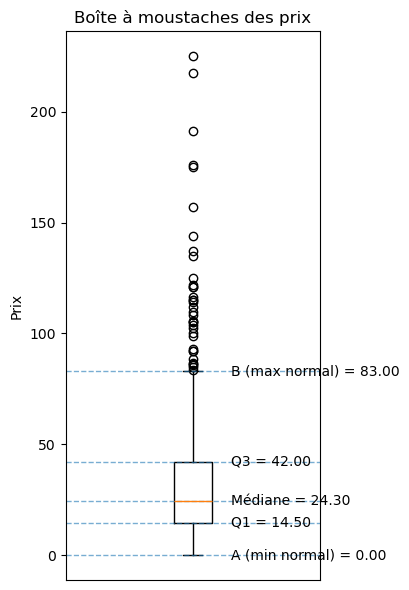

In [183]:
#Création d'une boîte à moustache de la répartition des prix grâce à Pandas
# colonne de prix (price_2 si elle existe, sinon price)
col_prix = "price_2" if "price_2" in df_erp.columns else "price"

# série numérique SANS NaN 
s = pd.to_numeric(df_erp[col_prix], errors="coerce").dropna()

# quartiles, médiane, IQR
Q1, Med, Q3 = s.quantile([0.25, 0.50, 0.75])
IQR = Q3 - Q1

#  bornes "normales" pour moustaches
borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

# moustaches A et B (valeurs extrêmes encore dans l'intervalle normal)
A = s[s >= borne_basse].min()  # moustache basse
B = s[s <= borne_haute].max()  # moustache haute

# outliers (points isolés)
outliers_mask = (s < borne_basse) | (s > borne_haute)
nb_outliers = int(outliers_mask.sum())

# --- Affichage des chiffres 
print(f"Q1 = {Q1:.2f}")
print(f"Médiane = {Med:.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"IQR = Q3 - Q1 = {IQR:.2f}")
print(f"A (moustache basse) = {A:.2f}")
print(f"B (moustache haute) = {B:.2f}")
print(f"Outliers = {nb_outliers} valeur(s)")

#  tracé d'une boîte à moustaches 
plt.figure(figsize=(4,6))
plt.boxplot(s, vert=True, showfliers=True)  # outliers visibles
plt.xticks([])
plt.ylabel("Prix")
plt.title("Boîte à moustaches des prix")

# annotations des lignes Q1 / Médiane / Q3 / A / B
def hline(val, label):
    plt.axhline(val, linestyle="--", linewidth=1, alpha=0.6)
    plt.text(1.15, val, f"{label} = {val:.2f}", va="center")

hline(Q1, "Q1")
hline(Med, "Médiane")
hline(Q3, "Q3")
hline(A, "A (min normal)")
hline(B, "B (max normal)")

plt.tight_layout()
plt.show()

In [184]:
#Autre méthode avec plotly express
import plotly.express as px

#colonne de prix
col_prix = "price_2" if "price_2" in df_erp.columns else "price"

#Transformer en numérique et retirer seulement les NaN 
s = pd.to_numeric(df_erp[col_prix], errors="coerce").dropna()

Q1, Med, Q3 = s.quantile([0.25, 0.50, 0.75])
print(f"Q1 = {Q1:.2f} | Médiane = {Med:.2f} | Q3 = {Q3:.2f}")

#  Tracer la boîte à moustaches 
fig = px.box(
    y=s,
    #(points = outliers visibles)
    points="outliers",
    labels={"y": "Prix"},
    title="Répartition des prix (Plotly Express)"
)
fig.show()

Q1 = 14.50 | Médiane = 24.30 | Q3 = 42.00


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le Z-index</h3>
</div>

In [185]:
#_________________Calculer la moyenne du prix___________________________________________
#_________________Calculer l'écart-type du prix_________________________________________
# colonne de prix 
col_prix = "price_2" if "price_2" in df_erp.columns else "price"
# La transformer en numérique (les non-numériques deviennent NaN)
s = pd.to_numeric(df_erp[col_prix], errors="coerce")
# On enlève juste les NaN pour calculer correctement
s_clean = s.dropna()
#______ (μ) moyenne_____________
moyenne = s_clean.mean()
#______  (σ)(écart-type )________
ecart_type = s_clean.std(ddof=1)  
display(Markdown(f"**Moyenne (μ)** = {moyenne:.2f} — **Écart-type (σ)** = {ecart_type:.2f}"))
#_________________Calculer le Z-score____________________________
#_____________ Z-score On applique la formule (z= prix−μ/σ )_____
# Z-score pour chaque valeur de prix ( Chaque prix devient un nombre d’écarts-types)
z = (s - moyenne) / ecart_type
# On le remet dans le tableau
df_erp = df_erp.copy()
df_erp["z_score_prix"] = z

# 5) Aperçu 
display(Markdown("**Aperçu `df_erp` avec Z-score (toutes colonnes)**"))
display(df_erp.head(10).style.format({"z_score_prix": "{:.2f}"}))

# Top 10 (|z| le plus grand) lister les prix les plus éloignés
top_idx = df_erp["z_score_prix"].abs().sort_values(ascending=False).head(10).index
display(Markdown("**Top 10 des valeurs les plus éloignées (|z| max)**"))
display(df_erp.loc[top_idx].style.format({"z_score_prix": "{:.2f}"}))



**Moyenne (μ)** = 32.23 — **Écart-type (σ)** = 26.65

**Aperçu `df_erp` avec Z-score (toutes colonnes)**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,z_score_prix
0,3847,1,24.200000,16,instock,12.880000,24.200000,16,en_ligne,-0.30
1,3849,1,34.300000,10,instock,17.540000,34.300000,10,en_ligne,0.08
2,3850,1,20.800000,0,outofstock,10.640000,20.800000,0,en_ligne,-0.43
3,4032,1,14.100000,26,instock,6.920000,14.100000,26,en_ligne,-0.68
4,4039,1,46.000000,3,instock,23.770000,46.000000,3,en_ligne,0.52
5,4040,1,34.300000,12,instock,18.250000,34.300000,12,en_ligne,0.08
6,4041,1,32.700000,12,instock,17.570000,32.700000,12,en_ligne,0.02
7,4042,1,31.200000,15,instock,15.480000,31.200000,15,en_ligne,-0.04
8,4043,1,60.000000,0,outofstock,29.450000,60.000000,0,en_ligne,1.04
9,4045,1,42.600000,5,instock,22.010000,42.600000,5,en_ligne,0.39


**Top 10 des valeurs les plus éloignées (|z| max)**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,z_score_prix
208,4352,1,225.000000,0,outofstock,137.810000,225.000000,0,en_ligne,7.23
460,5001,1,217.500000,18,instock,116.870000,217.500000,18,en_ligne,6.95
635,5892,1,191.300000,98,instock,116.060000,191.300000,98,en_ligne,5.97
227,4402,1,176.000000,11,instock,78.250000,176.000000,11,en_ligne,5.40
598,5767,1,175.000000,12,instock,90.420000,175.000000,12,en_ligne,5.36
230,4406,1,157.000000,12,instock,69.080000,157.000000,12,en_ligne,4.68
242,4594,1,144.000000,0,outofstock,87.360000,144.000000,0,en_ligne,4.19
411,4904,1,137.000000,9,instock,67.950000,137.000000,9,en_ligne,3.93
697,6126,1,135.000000,138,instock,80.330000,135.000000,138,en_ligne,3.86
556,5612,1,124.800000,19,instock,66.410000,124.800000,19,en_ligne,3.47


In [186]:
#Quel est le seuil prix dont le z-score est supérieur à 3?
#Le seuil de prix pour avoir un z-score > 3  : seuilhaut = (moyenne + 3 × écart-type) --> (Seuil haut :32.23+3×26.65 =112.18)
#Donc tout prix > environ 112.18 aura un z-score > 3
# 'moyenne' et 'ecart_type' sont déjà calculés
seuil_haut = moyenne + 3 * ecart_type
seuil_bas  = moyenne - 3 * ecart_type 

# Articles au-dessus du seuil (z > 3)
df_erp_zsup3 = df_erp[df_erp["price"] > seuil_haut]

col_prix = "price_2" if "price_2" in df_erp.columns else "price"

# Filtre des articles au-dessus du seuil (z > 3)
df_erp_zsup3 = df_erp[df_erp[col_prix] > seuil_haut].copy()

# Tri pour voir les plus chers en premier
df_erp_zsup3 = df_erp_zsup3.sort_values(by=col_prix, ascending=False)

# Affichage
display(Markdown(f"**le nombre de lignes dont le prix est > seuil_haut (z > 3): {len(df_erp_zsup3)}**"))
display(Markdown(f"**Articles avec z > 3 (prix > {seuil_haut:.2f})**"))
display(df_erp_zsup3.head(10)) 

**le nombre de lignes dont le prix est > seuil_haut (z > 3): 17**

**Articles avec z > 3 (prix > 112.17)**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,z_score_prix
208,4352,1,225.0,0,outofstock,137.81,225.0,0,en_ligne,7.234577
460,5001,1,217.5,18,instock,116.87,217.5,18,en_ligne,6.953101
635,5892,1,191.3,98,instock,116.06,191.3,98,en_ligne,5.969813
227,4402,1,176.0,11,instock,78.25,176.0,11,en_ligne,5.395602
598,5767,1,175.0,12,instock,90.42,175.0,12,en_ligne,5.358072
230,4406,1,157.0,12,instock,69.08,157.0,12,en_ligne,4.682530
242,4594,1,144.0,0,outofstock,87.36,144.0,0,en_ligne,4.194639
411,4904,1,137.0,9,instock,67.95,137.0,9,en_ligne,3.931928
697,6126,1,135.0,138,instock,80.33,135.0,138,en_ligne,3.856868
556,5612,1,124.8,19,instock,66.41,124.8,19,en_ligne,3.474061


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [187]:
#________Utilisation de la fonction "describe" de Pandas pour l'étude des mesures de dispersion________________________
# colonne de prix 
col_prix = "price_2" if "price_2" in df_erp.columns else "price"

# Convertir en numérique (les valeurs non-numériques deviennent NaN)
s = pd.to_numeric(df_erp[col_prix], errors="coerce")

# describe() :(count, mean(moyenne), std(écart-type), min, 25%(Q1), 50%(médiane), 75%(Q3), max)
res = s.describe()

# Affichage #mesures de dispersion (écart-type + étendue via min/max + quartiles)
display(Markdown(f"### Résultat`describe()` sur `{col_prix}`"))
display(res.to_frame(name="valeur").round(2))


### Résultat`describe()` sur `price_2`

,valeur
count,825.00
mean,32.23
std,26.65
min,0.00
25%,14.50
50%,24.30
75%,42.00
max,225.00


In [188]:
#Définir un seuil pour les articles "outliers" en prix
# Calculer Q1, Q3 et IQR (cœur des données)
#25% des valeurs en-dessous
Q1 = s.quantile(0.25)
#75% en-dessous
Q3 = s.quantile(0.75)
IQR = Q3 - Q1

# Définir les SEUILS outliers
seuil_bas  = Q1 - 1.5 * IQR
seuil_haut = Q3 + 1.5 * IQR

#  Marquer les lignes hors de ces seuils
df_erp["outlier_iqr"] = (pd.to_numeric(df_erp[col_prix], errors="coerce") < seuil_bas) | \
                        (pd.to_numeric(df_erp[col_prix], errors="coerce") > seuil_haut)

# aperçu
nb_out = int(df_erp["outlier_iqr"].sum())
display(Markdown(f"**Seuils IQR** :---> bas = **{seuil_bas:.2f}** ---> haut = **{seuil_haut:.2f}**  ----> Outliers détectés : **{nb_out}**"))
display(df_erp.loc[df_erp["outlier_iqr"], [col_prix]].head(10))

**Seuils IQR** :---> bas = **-26.75** ---> haut = **83.25**  ----> Outliers détectés : **36**

,price_2
19,86.1
66,100.0
68,88.4
208,225.0
214,85.6
227,176.0
228,108.5
230,157.0
231,104.0
240,109.6


**Outliers prix (méthode IQR)**

- Articles avec un prix : **825**

- Nombre d’outliers : **36**

- Proportion d’outliers : **4.4%**

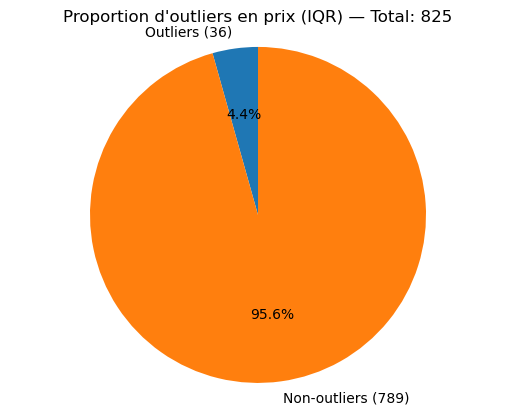

- Articles avec un prix : **825**

- Outliers : **36** (4.4%)

- Non-outliers : **789** (95.6%)

In [189]:
#_________Définir le nombre d'articles et la proportion de l'ensemble du catalogue "outliers"_________________________
# Compter les lignes qui ont un prix (évite les NaN)
nb_avec_prix = int(s.notna().sum())
nb_outliers  = int(df_erp.loc[s.notna(), "outlier_iqr"].sum())
part_outliers = (nb_outliers / nb_avec_prix * 100) if nb_avec_prix > 0 else 0.0

# Affichage 
display(Markdown("**Outliers prix (méthode IQR)**"))
display(Markdown(f"- Articles avec un prix : **{nb_avec_prix}**"))
display(Markdown(f"- Nombre d’outliers : **{nb_outliers}**"))
display(Markdown(f"- Proportion d’outliers : **{part_outliers:.1f}%**"))

#__________________________________grapphique qui montre la proportion (%) d’outliers_______________________________________________
# Calcul Non-outliers
nb_non_outliers = nb_avec_prix - nb_outliers

# Labels et valeurs
labels = [f"Outliers ({nb_outliers})", f"Non-outliers ({nb_non_outliers})"]
sizes  = [nb_outliers, nb_non_outliers]

# Camembert
plt.figure()
plt.pie(
    sizes,
    labels=labels,
    autopct=lambda p: f"{p:.1f}%",   # affiche le pourcentage sur chaque part
    startangle=90
)
plt.title(f"Proportion d'outliers en prix (IQR) — Total: {nb_avec_prix}")
plt.axis('equal')  # camembert circulaire
plt.show()

# Rappel 
display(Markdown(f"- Articles avec un prix : **{nb_avec_prix}**"))
display(Markdown(f"- Outliers : **{nb_outliers}** ({part_outliers:.1f}%)"))
display(Markdown(f"- Non-outliers : **{nb_non_outliers}** ({100 - part_outliers:.1f}%)"))


In [190]:
#Selon vous, ces outliers sont-ils justifiés ? Comment le démontrer si cela est possible ?
#_________________________ces outliers sont-ils justifiés ?___________________________________________
#Pour chaque outlier on pose 3 questions très concrètes :
#1)La marge est-elle logique ?
#Si prix ≥ prix d’achat et marge% entre ~25% et 60% --> justifié
#Si marge négative (prix < prix d’achat) --> suspect.

#2)Est-ce que ça se vend ? ( total_sales ,product_type)
#Outlier qui ce vend --> souvent un produit premium (champagne/cognac haut de gamme --> prix élevés attendus.) justifié.
#Outlier sans ventes (depuis longtemps) --> à vérifier --> suspect.

#Pourquoi la rareté peut justifier un prix élevé ?
#Idée simple : un article très peu disponible (ex. stock ≤ 2) peut être légitimement plus cher : fin de série, rare, édition limitée
#Comment l’interpréter
#Stock ≤ 2 + prix outlier --> probablement justifié (produit rare).
#Stock 0 : peut signifier épuisé (la rareté).
#Stock bas + ventes > 0 --> la demande existe, le prix élevé est cohérent.
#Stock bas + aucune vente depuis longtemps --> rare mais à surveiller
#__________________Comment le démontrer si cela est possible ?__________________________________
# _____________1) cas Marge __________________________________________________________________
# === 1) OUTLIERS  marge 
col_prix = "price_2" if "price_2" in df_erp.columns else "price"
erp = df_erp.copy()
erp["marge_pct"] = ((erp[col_prix] - erp["purchase_price"]) / erp[col_prix]) * 100

ok = erp["outlier_iqr"] & erp["marge_pct"].between(25, 60, inclusive="both")
ko = erp["outlier_iqr"] & ((erp["marge_pct"] < 0) | (erp["marge_pct"] > 80))

# Markdown attend une chaîne, pas des arguments séparés
display(Markdown(
    f"**Outliers (IQR)** : {int(erp['outlier_iqr'].sum())}  |  "
    f"**Justifiés (marge 25–60%)** : {int(ok.sum())}  |  "
    f"**Suspects (marge <0% ou >80%)** : {int(ko.sum())}"
))

show_cols_erp = [c for c in ["product_id", col_prix, "purchase_price", "marge_pct", "z_score_prix"] if c in erp.columns]
aff_ko = erp.loc[ko, show_cols_erp].copy()
aff_ko["marge_pct"] = aff_ko["marge_pct"].round(1).astype(str) + " %"
display(aff_ko.head(10))
#constat: 35 outliers chers restent cohérents grâce à une marge saine,une marge comprise entre 25 % et 60 %. C’est une marge “normale”
#1 outlier est réellement problématique car la marge est négative
#son prix est à ~2.24 écarts-types de la moyenne
#_______________________ 2) cas vente______________________________________________________________
# === 2) OUTLIERS qui VENDENT (
final = df_final.copy()
# récupérer outlier/marge 
if "outlier_iqr" not in final.columns:
    final["outlier_iqr"] = final["product_id"].map(erp.set_index("product_id")["outlier_iqr"])
if "marge_pct" not in final.columns:
    final["marge_pct"] = final["product_id"].map(erp.set_index("product_id")["marge_pct"])

# filtre : outlier & ventes > 0
vend = final["outlier_iqr"].fillna(False) & (pd.to_numeric(final["total_sales"], errors="coerce").fillna(0) > 0)
nb_vend = int(vend.sum())
display(Markdown(f"**Outliers qui ont des ventes : {nb_vend}**"))

# affichage
show_cols_final = [c for c in ["product_id", "post_title", col_prix, "purchase_price",
                               "marge_pct", "product_type", "total_sales"] if c in final.columns]

aff = final.loc[vend, show_cols_final].copy()
if "marge_pct" in aff.columns:
    aff["marge_pct"] = pd.to_numeric(aff["marge_pct"], errors="coerce").round(1).astype(str) + " %"

display(aff.head(10))
#constat:On a isolé les produits dont le prix est un outlier (méthode IQR) et qui ont des ventes.
#La plupart affichent des marges 40–55 % et appartiennent à des catégories premium (Champagne, Cognac, grands vins).
#Ça indique que ces prix élevés sont probablement justifiés ( haut de gamme) plutôt que des erreurs.
#____________________________________________3) cas rareté __________________________________________
# --- Cas 3 : Outliers "rares" (stock très faible) ---
# Rareté = outlier de prix = True ET stock ≤ 2
mask_rare = final["outlier_iqr"].fillna(False) & (pd.to_numeric(final["stock_quantity"], errors="coerce") <= 2)

# colonnes à afficher
cols = [c for c in ["product_id","post_title",col_prix,"purchase_price","marge_pct",
                    "stock_quantity","product_type","total_sales"] if c in final.columns]
# On extrait seulement les lignes rares 
apercu = final.loc[mask_rare, cols].copy()
#marge en pourcentage propre
if "marge_pct" in apercu.columns:
    apercu["marge_pct"] = pd.to_numeric(apercu["marge_pct"], errors="coerce").round(1).astype(str) + " %"

# Résultat
display(Markdown(f"**Outliers “rares” (stock ≤ 2)** : {int(mask_rare.sum())}"))
display(apercu.head(10))
#constat: #Ces 9 produits sont chers et quasi épuisés.
#Souvent, prix élevé + rareté = justifié si le produit est épuisé ,édition limitée et premium, le prix élevé est défendable.
#Marge : la majorité est entre 40–56 % --> cohérent.
#Anomalies : total_sales négatifs pour plusieurs vins -->donnée à corriger

**Outliers (IQR)** : 36  |  **Justifiés (marge 25–60%)** : 35  |  **Suspects (marge <0% ou >80%)** : 1

,product_id,price_2,purchase_price,marge_pct,z_score_prix
724,6324,92.0,99.0,-7.6 %,2.243074


**Outliers qui ont des ventes : 32**

,product_id,post_title,price_2,purchase_price,marge_pct,product_type,total_sales
69,4115,Zind-Humbrecht Riesling Grand Cru Rangen De Th...,100.0,52.70,47.3 %,Vin,1.0
71,4132,Zind-Humbrecht Pinot Gris Grand Cru Rangen De ...,88.4,44.30,49.9 %,Vin,5.0
216,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,137.81,38.8 %,Champagne,11.0
222,4359,Champagne Larmandier-Bernier Grand Cru Les Che...,85.6,51.93,39.3 %,Champagne,7.0
235,4402,Cognac Frapin VIP XO,176.0,78.25,55.5 %,Cognac,3.0
236,4404,Cognac Frapin Château de Fontpinot XO,108.5,52.22,51.9 %,Cognac,4.0
238,4406,Cognac Frapin Château de Fontpinot 1989 20 Ans...,157.0,69.08,56.0 %,Cognac,4.0
239,4407,Cognac Frapin Cigar Blend,104.0,46.71,55.1 %,Cognac,5.0
251,4582,Château de Meursault Puligny-Montrachet 1er Cr...,109.6,53.80,50.9 %,Vin,1.0
434,4903,Domaine Des Croix Corton Grand Cru Les Grèves ...,102.3,51.80,49.4 %,Vin,2.0


**Outliers “rares” (stock ≤ 2)** : 9

,product_id,post_title,price_2,purchase_price,marge_pct,stock_quantity,product_type,total_sales
19,4055,Pierre Jean Villa Condrieu Jardin Suspendu 2018,86.1,37.88,56.0 %,0,Vin,-56.0
20,4055,Pierre Jean Villa Côte Rôtie Fongeant 2017,86.1,37.88,56.0 %,0,Vin,-17.0
216,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,137.81,38.8 %,0,Champagne,11.0
253,4594,Pierre Jean Villa Condrieu Jardin Suspendu 2018,144.0,87.36,39.3 %,0,Vin,-56.0
254,4594,Pierre Jean Villa Côte Rôtie Fongeant 2017,144.0,87.36,39.3 %,0,Vin,-17.0
514,5070,Pierre Jean Villa Condrieu Jardin Suspendu 2018,84.7,47.43,44.0 %,0,Vin,-56.0
515,5070,Pierre Jean Villa Côte Rôtie Fongeant 2017,84.7,47.43,44.0 %,0,Vin,-17.0
576,5565,Tempier Bandol Cabassaou 2017,92.0,46.11,49.9 %,0,Vin,1.0
684,5916,Wemyss Malts Single Cask Scotch Whisky Chocola...,93.0,40.49,56.5 %,1,Whisky,1.0


<div style="background-color: #f8b4b4;">
  <div style="border: 1px solid #ffffff;">
    <h3 style="margin: auto; padding: 20px; color: #ffffff;">
      4.3 - Amélioration avec l'IA : Isolation Forest comparé à l'IQR
    </h3>
  </div>
</div>

**Pourquoi cette amélioration ?**

Avec l'IQR, je regarde seulement le prix. Un vin cher est signalé, même s'il est normal (vin haut de gamme).
J'ai dû vérifier la marge à la main pour savoir si c'était une erreur.

Ici, je teste **Isolation Forest** : un algorithme de machine learning qui regarde plusieurs colonnes en même temps
(prix, prix d'achat, marge, stock, ventes, type de produit).
Je compare ses résultats avec ceux de mon IQR. Je ne supprime aucun produit : je les signale pour les vérifier.

Méthode choisie après ma veille : voir `docs/veille.md` et `journal_IA.md`.

In [210]:
# =====================================================================
# 4.3 - Isolation Forest comparé à l'IQR
# But : trouver les produits au profil bizarre en regardant
#       PLUSIEURS colonnes en même temps (pas seulement le prix)
# =====================================================================

# --- On importe les outils de scikit-learn (la librairie de machine learning) ---
from sklearn.ensemble import IsolationForest       # l'algorithme qui repère les profils bizarres
from sklearn.compose import ColumnTransformer      # prépare chaque type de colonne différemment
from sklearn.pipeline import Pipeline              # enchaîne les étapes : préparer puis calculer
from sklearn.impute import SimpleImputer           # remplit les cases vides
from sklearn.preprocessing import OneHotEncoder    # transforme un texte (ex. "Vin rouge") en colonnes 0/1

# ---------------------------------------------------------------------
# ÉTAPE 1 : préparer les données (une ligne = un produit)
# ---------------------------------------------------------------------

# Le nom de ma colonne prix ("price_2" si je l'ai créée, sinon "price")
col_prix = "price_2" if "price_2" in df_final.columns else "price"

# Je pars de mon tableau fusionné df_final, et je garde une seule ligne par produit
data = df_final.drop_duplicates(subset="product_id").copy()

# Je récupère le résultat de mon IQR (calculé plus haut dans df_erp)
# True = le prix est anormal selon l'IQR, False = le prix est normal
iqr_par_produit = dict(zip(df_erp["product_id"].astype(int), df_erp["outlier_iqr"]))
data["outlier_iqr"] = data["product_id"].astype(int).map(iqr_par_produit).fillna(False).astype(bool)

# Je transforme ces colonnes en nombres (si une case contient du texte, elle devient vide)
for c in [col_prix, "purchase_price", "stock_quantity", "total_sales"]:
    data[c] = pd.to_numeric(data[c], errors="coerce")

# Je calcule la marge en euros : prix de vente - prix d'achat
data["marge"] = data[col_prix] - data["purchase_price"]

# Je calcule le taux de marge : marge / prix de vente (ex. 0.40 = 40 %)
# Si le prix vaut 0, la division donne l'infini : je le remplace par une case vide
data["taux_marge"] = (data["marge"] / data[col_prix]).replace([np.inf, -np.inf], np.nan)

# Les colonnes que l'algorithme va regarder
variables_numeriques = [col_prix, "purchase_price", "marge", "taux_marge", "stock_quantity", "total_sales"]
variables_categorielles = ["product_type"] if "product_type" in data.columns else []

# ---------------------------------------------------------------------
# ÉTAPE 2 : préparer les colonnes pour l'algorithme
# L'algorithme ne comprend que des nombres, sans cases vides
# ---------------------------------------------------------------------
preparation = ColumnTransformer(transformers=[
    # Colonnes de nombres : une case vide est remplacée par la médiane de la colonne
    ("numerique", SimpleImputer(strategy="median"), variables_numeriques),
    # Colonne texte (type de produit) : case vide -> "inconnu", puis transformation en colonnes 0/1
    ("categorie", Pipeline(steps=[
        ("remplacer_manquant", SimpleImputer(strategy="constant", fill_value="inconnu")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), variables_categorielles)
])

# Fonction qui lance Isolation Forest avec un réglage donné
# "taux" = la part de produits que je demande à l'algorithme de signaler (ex. 0.05 = 5 %)
def lancer_iforest(taux):
    modele = Pipeline(steps=[
        ("preparation", preparation),
        # random_state=42 = la "seed" : le résultat est le même à chaque lancement
        ("isolation_forest", IsolationForest(contamination=taux, random_state=42))
    ])
    # L'algorithme répond -1 pour un produit bizarre, 1 pour un produit normal
    # Je transforme ça en True (bizarre) / False (normal)
    return modele.fit_predict(data[variables_numeriques + variables_categorielles]) == -1

# ---------------------------------------------------------------------
# ÉTAPE 3 : tester 3 réglages (2 %, 5 %, 8 %) et comparer avec l'IQR
# Si un produit est signalé avec les 3 réglages, il est vraiment bizarre
# ---------------------------------------------------------------------
resultats = []
for taux in [0.02, 0.05, 0.08]:
    iforest = lancer_iforest(taux)
    resultats.append({
        "réglage": f"{int(taux*100)} %",
        "outliers IQR": int(data["outlier_iqr"].sum()),
        "outliers Isolation Forest": int(iforest.sum()),
        "trouvés par les deux": int((iforest & data["outlier_iqr"]).sum()),
        "IQR seulement": int((~iforest & data["outlier_iqr"]).sum()),
        "Isolation Forest seulement": int((iforest & ~data["outlier_iqr"]).sum()),
        "marge négative trouvée ?": bool((iforest & (data["marge"] < 0)).any()),
    })

display(Markdown("**Comparaison IQR / Isolation Forest selon le réglage**"))
display(pd.DataFrame(resultats))

# ---------------------------------------------------------------------
# ÉTAPE 4 : je garde le réglage 5 % et j'affiche les produits à vérifier
# ---------------------------------------------------------------------
data["outlier_iforest"] = lancer_iforest(0.05)

# Les colonnes que je veux voir pour comprendre chaque produit
colonnes_affichees = ["product_id", "post_title", col_prix, "purchase_price", "marge", "taux_marge",
                      "stock_quantity", "total_sales", "product_type"]
colonnes_affichees = [c for c in colonnes_affichees if c in data.columns]  # je garde celles qui existent

# J'affiche 3 listes, du plus cher au moins cher (15 produits maximum par liste)
for titre, masque in [
    ("Trouvés par les deux méthodes (à vérifier en premier)", data["outlier_iqr"] & data["outlier_iforest"]),
    ("Trouvés par l'IQR seulement", data["outlier_iqr"] & ~data["outlier_iforest"]),
    ("Trouvés par Isolation Forest seulement", ~data["outlier_iqr"] & data["outlier_iforest"]),
]:
    display(Markdown(f"**{titre} : {int(masque.sum())}**"))
    display(data.loc[masque, colonnes_affichees].sort_values(col_prix, ascending=False).head(15))

# ---------------------------------------------------------------------
# ÉTAPE 5 : je signale, je ne supprime rien
# a_verifier = True si au moins une des deux méthodes trouve le produit bizarre
# ---------------------------------------------------------------------
data["a_verifier"] = data["outlier_iqr"] | data["outlier_iforest"]
display(Markdown(f"**Nombre total de produits à vérifier : {int(data['a_verifier'].sum())}**"))

**Comparaison IQR / Isolation Forest selon le réglage**

,réglage,outliers IQR,outliers Isolation Forest,trouvés par les deux,IQR seulement,Isolation Forest seulement,marge négative trouvée ?
0,2 %,36,17,13,23,4,True
1,5 %,36,42,17,19,25,True
2,8 %,36,66,20,16,46,True


**Trouvés par les deux méthodes (à vérifier en premier) : 17**

,product_id,post_title,price_2,purchase_price,marge,taux_marge,stock_quantity,total_sales,product_type
216,4352,Champagne Egly-Ouriet Grand Cru Millésimé 2008,225.0,137.81,87.19,0.387511,0,11.0,Champagne
486,5001,David Duband Charmes-Chambertin Grand Cru 2014,217.5,116.87,100.63,0.462667,18,2.0,Vin
669,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,191.3,116.06,75.24,0.393309,98,6.0,Champagne
235,4402,Cognac Frapin VIP XO,176.0,78.25,97.75,0.555398,11,3.0,Cognac
630,5767,Camille Giroud Clos de Vougeot 2016,175.0,90.42,84.58,0.483314,12,4.0,Vin
238,4406,Cognac Frapin Château de Fontpinot 1989 20 Ans...,157.0,69.08,87.92,0.560000,12,4.0,Cognac
253,4594,Pierre Jean Villa Condrieu Jardin Suspendu 2018,144.0,87.36,56.64,0.393333,0,-56.0,Vin
733,6126,Champagne Gosset Célébris Vintage 2007,135.0,80.33,54.67,0.404963,138,5.0,Champagne
685,5917,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,122.0,54.24,67.76,0.555410,12,3.0,Whisky
686,5918,Wemyss Malts Single Cask Scotch Whisky Chai Ca...,114.0,52.25,61.75,0.541667,12,3.0,Whisky


**Trouvés par l'IQR seulement : 19**

,product_id,post_title,price_2,purchase_price,marge,taux_marge,stock_quantity,total_sales,product_type
435,4904,Domaine Des Croix Corton Charlemagne Grand Cru...,137.0,67.95,69.05,0.504015,9,3.0,Vin
588,5612,Domaine Weinbach Gewurztraminer Grand Cru Furs...,124.8,66.41,58.39,0.467869,19,1.0,Vin
745,6213,Domaine des Comtes Lafon Volnay 1er Cru Santen...,121.0,63.14,57.86,0.478182,9,3.0,Vin
748,6216,Domaine des Comtes Lafon Volnay 1er Cru Champa...,121.0,60.02,60.98,0.503967,14,2.0,Vin
739,6202,Domaine Clerget Echezeaux Grand Cru En Orveaux...,116.4,63.15,53.25,0.457474,12,5.0,Vin
744,6212,Domaine des Comtes Lafon Volnay 1er Cru Santen...,115.0,59.42,55.58,0.483304,16,7.0,Vin
747,6215,Domaine des Comtes Lafon Volnay 1er Cru Champa...,115.0,56.45,58.55,0.509130,14,4.0,Vin
251,4582,Château de Meursault Puligny-Montrachet 1er Cr...,109.6,53.80,55.80,0.509124,18,1.0,Vin
738,6201,David Duband Chambolle-Musigny 1er Cru Les Sen...,105.6,57.29,48.31,0.457481,16,6.0,Vin
492,5008,Domaine des Comtes Lafon Volnay 1er Cru Santen...,105.0,56.42,48.58,0.462667,12,7.0,Vin


**Trouvés par Isolation Forest seulement : 25**

,product_id,post_title,price_2,purchase_price,marge,taux_marge,stock_quantity,total_sales,product_type
213,4337,Champagne Mailly Grand Cru Les Echansons 2007,83.0,48.90,34.10,0.410843,145,0.0,Champagne
217,4353,Champagne Egly-Ouriet Grand Cru Brut Rosé,79.5,45.91,33.59,0.422516,127,14.0,Champagne
215,4350,Champagne Egly-Ouriet Grand Cru Extra Brut V.P.,79.5,47.30,32.20,0.405031,145,7.0,Champagne
221,4358,Champagne Larmandier-Bernier Grand Cru Vieille...,77.0,47.16,29.84,0.387532,81,8.0,Champagne
81,4149,Champagne Mailly Grand Cru Intemporelle Rosé 2009,69.0,40.25,28.75,0.416667,101,5.0,Champagne
237,4405,Cognac Frapin Château de Fontpinot XO 1/2,68.1,32.46,35.64,0.523348,15,7.0,Cognac
234,4401,Cognac Frapin VSOP,62.5,27.21,35.29,0.564640,5,3.0,Cognac
505,5027,Champagne Agrapart &amp; Fils Terroirs Brut Bl...,62.1,38.04,24.06,0.387440,79,6.0,Champagne
229,4396,Wemyss Malts Blended Malt Scotch Whisky The Hi...,62.0,28.42,33.58,0.541613,0,0.0,Whisky
690,5932,Cognac Normandin Mercier VFC,59.9,27.18,32.72,0.546244,13,0.0,Cognac


**Nombre total de produits à vérifier : 61**

In [ ]:
# =====================================================================
# 4.3 (suite) - Écrire une raison pour chaque produit à vérifier
# But : ne pas laisser une simple alerte, mais dire POURQUOI le produit est signalé
# =====================================================================


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge ainsi qu'une analyse multivariée  </h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [191]:
##############################
# Calculer le CA du site web #
##############################

#_________________Créer une colonne calculant le CA par article__________________________________________________
#Pour chaque article, on calcule :
#CA_par_article = prix_unitaire × quantité_vendue
#_______________Calculer la somme de la colonne "ca_par_article"______________________________________________
#On additionne tous les CA_par_article --> ça donne le CA total du site.
#Ce résultat correspond au chiffre d'affaire du site web

col_prix = "price_2" if "price_2" in df_final.columns else "price"

#On force prix et quantités en numérique
df_final = df_final.copy()
df_final["prix_num"] = pd.to_numeric(df_final[col_prix], errors="coerce")
df_final["qte_num"]  = pd.to_numeric(df_final["total_sales"], errors="coerce").fillna(0)

# ignorer des quantités négatives 
df_final["qte_num"] = df_final["qte_num"].clip(lower=0)

# CA par article = prix_unitaire × quantité_vendue
df_final["ca_par_article"] = df_final["prix_num"] * df_final["qte_num"]
#  CA total (somme)
ca_total = float(df_final["ca_par_article"].sum())

# Affichage
display(Markdown(f"**chiffre d'affaire total du site web: {ca_total:,.2f}**"))
display(df_final[["product_id","post_title",col_prix,"total_sales","ca_par_article"]]
        .head(10))


**chiffre d'affaire total du site web: 143,680.10**

,product_id,post_title,price_2,total_sales,ca_par_article
0,3847,Pierre Jean Villa Saint-Joseph Préface 2018,24.2,6.0,145.2
1,3849,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,34.3,9.0,308.7
2,3850,Pierre Jean Villa Crozes-Hermitage Accroche Co...,20.8,0.0,0.0
3,4032,Pierre Jean Villa IGP Collines Rhodaniennes Ga...,14.1,12.0,169.2
4,4039,Pierre Jean Villa Côte Rôtie Carmina 2017,46.0,3.0,138.0
5,4040,Pierre Jean Villa Saint-Joseph Saut De l'Ange ...,34.3,7.0,240.1
6,4041,Pierre Gaillard Condrieu 2018,32.7,6.0,196.2
7,4042,Pierre Gaillard Cornas 2017,31.2,8.0,249.6
8,4043,Pierre Gaillard Côte Rôtie Esprit de Blonde 2017,60.0,0.0,0.0
9,4045,Pierre Gaillard Côte Rôtie 2018,42.6,3.0,127.8


Q1 = 35.80
Médiane = 140.80
Q3 = 217.03


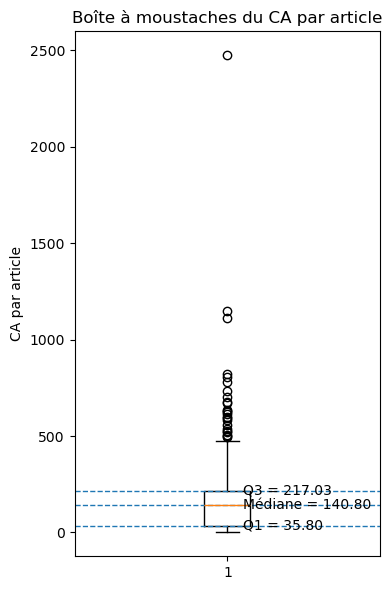

In [192]:
#____________________________(boîte à moustaches) de ca_par_article_______________________________
# on convertit et on enlève les NaN
ca = pd.to_numeric(df_final["ca_par_article"], errors="coerce").dropna()

# Quartiles + médiane
s = df_final["ca_par_article"].dropna()
Q1, Med, Q3 = s.quantile([0.25, 0.50, 0.75])

print(f"Q1 = {Q1:.2f}")
print(f"Médiane = {Med:.2f}")
print(f"Q3 = {Q3:.2f}")

# 3) Boxplot annoté
plt.figure(figsize=(4,6))
plt.boxplot(s, vert=True, showfliers=True)
plt.ylabel("CA par article")
plt.title("Boîte à moustaches du CA par article")

for val, label in [(Q1, "Q1"), (Med, "Médiane"), (Q3, "Q3")]:
    plt.axhline(val, linestyle="--", linewidth=1)
    plt.text(1.05, val, f"{label} = {val:.2f}", va="center")

plt.tight_layout()
plt.show()

#resultat:outliers (quelques articles font un CA très élevé).

In [193]:
###############################
# Palmarès des articles en CA #
###############################

#______________________Effectuer le tri dans l'ordre décroissant du CA du dataset df_merge_________________________________________
#______________________Réinitialiser l'index du dataset par un reset_index__________________________________________
#______________________Afficher les 20 premiers articles en CA_________________________________________
#  Ramener le CA (déjà calculé dans df_final) côté df_merge
ca_par_prod = df_final.groupby("product_id")["ca_par_article"].sum()
df_merge = df_merge.copy()
df_merge["ca_par_article"] = df_merge["product_id"].map(ca_par_prod).fillna(0)
#Trier par CA décroissant + reset de l'index
df_merge_trie = df_merge.sort_values("ca_par_article", ascending=False).reset_index(drop=True)
# Aperçu : les 20 premiers articles en CA
display(df_merge_trie.head(20))

#________________________Graphique en barre des 20 premiers articles avec plotly express___________________________________
# --- Top 20
top20 = df_merge_trie.head(20).copy()
# récupérer un product_type par product_id depuis df_final
map_type = (df_final.dropna(subset=["product_id"])
                    .drop_duplicates("product_id")
                    .set_index("product_id")["product_type"])

top20["product_type"] = top20["product_id"].map(map_type).fillna("NA")

# libellé "product_id — product_type"
top20["label"] = top20["product_id"].astype(str) + " — " + top20["product_type"].astype(str)

# --- Graphique ---
fig = px.bar(
    top20,
    x="ca_par_article",
    y="label",
    orientation="h",
    text=top20["ca_par_article"].round(0),
    title="Top 20 des articles par chiffre d'affaires",
    hover_data=["product_id", "product_type", "ca_par_article"]  # maintenant la colonne existe
)
fig.update_traces(texttemplate="%{text:.0f}", textposition="outside", cliponaxis=False)
fig.update_layout(
    height=700, xaxis_title="CA (€)", yaxis_title="Article",
    yaxis=dict(categoryorder="total ascending"),
    margin=dict(l=260, r=40, t=60, b=40)
)
fig.show()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article
0,4352,1,225.0,0,outofstock,137.81,225.0,0,en_ligne,15940,both,2475.0
1,5892,1,191.3,98,instock,116.06,191.3,98,en_ligne,14983,both,1147.8
2,4353,1,79.5,127,instock,45.91,79.5,127,en_ligne,12587,both,1113.0
3,5826,1,41.2,34,instock,21.71,41.2,34,en_ligne,15325,both,824.0
4,6212,1,115.0,16,instock,59.42,115.0,16,en_ligne,13996,both,805.0
5,5026,1,86.8,101,instock,50.13,86.8,101,en_ligne,13913,both,781.2
6,5008,1,105.0,12,instock,56.42,105.0,12,en_ligne,11602,both,735.0
7,5767,1,175.0,12,instock,90.42,175.0,12,en_ligne,15185,both,700.0
8,6126,1,135.0,138,instock,80.33,135.0,138,en_ligne,14923,both,675.0
9,5025,1,112.0,136,instock,68.60,112.0,136,en_ligne,13914,both,672.0


In [194]:
#############################
# Calculer le 20 / 80 en CA #
#############################

#________________Créer une colonne calculant la part du CA de la ligne dans le dataset______________________________________________
#  Part du CA de chaque article 
total_ca = df_merge["ca_par_article"].sum()
df_merge["part_ca"] = df_merge["ca_par_article"] / (total_ca if total_ca else 1.0)

# Même info en pourcentage (arrondi à 0,1)
df_merge["part_ca_pct"] = (df_merge["part_ca"] * 100).round(1).astype(str) + " %"

# Afficher  + le top 10 (TOUTES les colonnes)
display(Markdown(f"**CA total (somme de `ca_par_article`) : {total_ca:,.2f}**"))
#____________Créer une colonne réalisant la somme cumulative de la colonne précedemment créée_________________________________
# TRIE puis calcule de la SOMME CUMULATIVE sur ce  trie
df80 = (df_merge
        .sort_values("part_ca", ascending=False)
        .reset_index(drop=True))

df80["part_ca_cum"]     = df80["part_ca"].cumsum()
df80["part_ca_cum_pct"] = (df80["part_ca_cum"] * 100).map("{:.1f} %".format)

# --- Top 10 (avec les colonnes cumulatives ) 
display(Markdown("**Top 10 par part de CA (10 premières lignes de la table triée et cumulée les plus gros contributeurs au CA)**"))
display(df80.head(10))   
#___________#Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% du CA______________________________________

# --- Nombre d’articles nécessaires pour atteindre 80% du CA ---
mask = df80["part_ca_cum"] >= 0.80
n80  = int(mask.idxmax() + 1) if mask.any() else len(df80)
#Proportion que représente ce groupe dans tout le catalogue (en % des articles).
pct80 = (n80 / len(df80) * 100) if len(df80) > 0 else 0.0
display(Markdown(f"**Articles nécessaires pour 80% du CA : {n80} ({pct80:.1f}%)**"))

colonnes_vue = [c for c in ["product_id","ca_par_article","part_ca","part_ca_cum","part_ca_cum_pct"]
                if c in df80.columns]
 # aperçu du groupe 80/20
display(df80.loc[:n80-1, colonnes_vue].head(10)) 

#______________________Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web___________________________
# taille du catalogue (nb d'articles)
# == len(df_merge)
catalogue_total = len(df80)              

# proportion du groupe 80% dans le catalogue
pct_catalogue_80 = (n80 / catalogue_total * 100) if catalogue_total > 0 else 0.0

display(Markdown(
    f"**Proportion du catalogue couverte par le groupe 80% du CA : {n80}/{catalogue_total} = {pct_catalogue_80:.1f}%**"
))

**CA total (somme de `ca_par_article`) : 143,680.10**

**Top 10 par part de CA (10 premières lignes de la table triée et cumulée les plus gros contributeurs au CA)**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,part_ca_cum,part_ca_cum_pct
0,4352,1,225.0,0,outofstock,137.81,225.0,0,en_ligne,15940,both,2475.0,0.017226,1.7 %,0.017226,1.7 %
1,5892,1,191.3,98,instock,116.06,191.3,98,en_ligne,14983,both,1147.8,0.007989,0.8 %,0.025214,2.5 %
2,4353,1,79.5,127,instock,45.91,79.5,127,en_ligne,12587,both,1113.0,0.007746,0.8 %,0.032961,3.3 %
3,5826,1,41.2,34,instock,21.71,41.2,34,en_ligne,15325,both,824.0,0.005735,0.6 %,0.038696,3.9 %
4,6212,1,115.0,16,instock,59.42,115.0,16,en_ligne,13996,both,805.0,0.005603,0.6 %,0.044298,4.4 %
5,5026,1,86.8,101,instock,50.13,86.8,101,en_ligne,13913,both,781.2,0.005437,0.5 %,0.049735,5.0 %
6,5008,1,105.0,12,instock,56.42,105.0,12,en_ligne,11602,both,735.0,0.005116,0.5 %,0.054851,5.5 %
7,5767,1,175.0,12,instock,90.42,175.0,12,en_ligne,15185,both,700.0,0.004872,0.5 %,0.059723,6.0 %
8,6126,1,135.0,138,instock,80.33,135.0,138,en_ligne,14923,both,675.0,0.004698,0.5 %,0.064421,6.4 %
9,5025,1,112.0,136,instock,68.60,112.0,136,en_ligne,13914,both,672.0,0.004677,0.5 %,0.069098,6.9 %


**Articles nécessaires pour 80% du CA : 435 (52.7%)**

,product_id,ca_par_article,part_ca,part_ca_cum,part_ca_cum_pct
0,4352,2475.0,0.017226,0.017226,1.7 %
1,5892,1147.8,0.007989,0.025214,2.5 %
2,4353,1113.0,0.007746,0.032961,3.3 %
3,5826,824.0,0.005735,0.038696,3.9 %
4,6212,805.0,0.005603,0.044298,4.4 %
5,5026,781.2,0.005437,0.049735,5.0 %
6,5008,735.0,0.005116,0.054851,5.5 %
7,5767,700.0,0.004872,0.059723,6.0 %
8,6126,675.0,0.004698,0.064421,6.4 %
9,5025,672.0,0.004677,0.069098,6.9 %


**Proportion du catalogue couverte par le groupe 80% du CA : 435/825 = 52.7%**

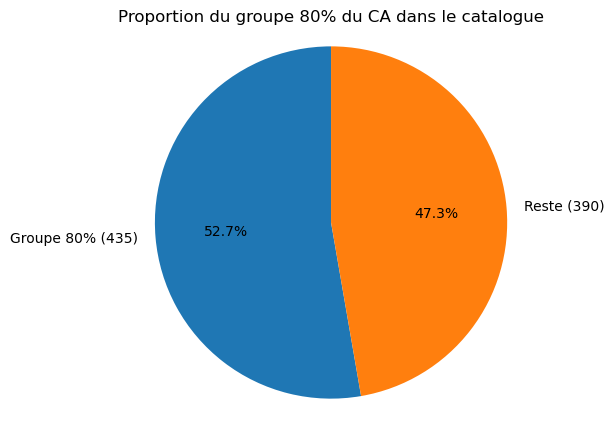

CA total : 143,680.10
Articles nécessaires pour 80% du CA : 435 / 825  (52.7%)


In [195]:
#______un camembert montrant la proportion du groupe qui cumule 80 % du CA par rapport au reste du catalogue._____________

# Part du CA par article + cumul (trié décroissant) ---
total_ca = pd.to_numeric(df_merge["ca_par_article"], errors="coerce").fillna(0).sum()
denom = total_ca if total_ca > 0 else 1.0
df80 = (
    df_merge.assign(part_ca = pd.to_numeric(df_merge["ca_par_article"], errors="coerce").fillna(0) / denom)
       .sort_values("part_ca", ascending=False)
       .reset_index(drop=True)
)
df80["part_ca_cum"] = df80["part_ca"].cumsum()

# --- 2) Taille du groupe qui atteint 80 % du CA ---
mask = df80["part_ca_cum"] >= 0.80
n80   = int(mask.idxmax() + 1) if mask.any() else len(df80)
reste = len(df80) - n80

# --- 3) Camembert ---
plt.figure(figsize=(5,5))
plt.pie([n80, reste],
        labels=[f"Groupe 80% ({n80})", f"Reste ({reste})"],
        autopct='%1.1f%%', startangle=90)
plt.title("Proportion du groupe 80% du CA dans le catalogue")
plt.axis('equal')    # camembert circulaire
plt.show()

# (Option) petit résumé
print(f"CA total : {total_ca:,.2f}")
print(f"Articles nécessaires pour 80% du CA : {n80} / {len(df80)}  ({n80/len(df80)*100:.1f}%)")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [196]:
#####################################
# Palmarès des articles en quantité #
#####################################
#_____________Effectuer le tri dans l'ordre décroissant de quantités vendues du dataset df_merge______________________
# On veut trier par quantités vendues. Si df_merge n'a pas 'total_sales',
# on la récupère depuis df_final grâce à product_id.____________________________________________
if "total_sales" not in df_merge.columns and "product_id" in df_merge.columns:
    qte_map = df_final.groupby("product_id")["total_sales"].sum(min_count=1)
    df_merge = df_merge.copy()
    df_merge["total_sales"] = df_merge["product_id"].map(qte_map)

# préparation quantités numériques , remplace les NaN par 0 et coupe les négatifs 
df_merge["total_sales"] = (
    pd.to_numeric(df_merge["total_sales"], errors="coerce").fillna(0).clip(lower=0)
)

#___________Réinitialiser l'index du dataset par un reset_index___________________________________________
df_merge = df_merge.sort_values("total_sales", ascending=False).reset_index(drop=True)

#________________Afficher les 20 premiers articles en quantité_____________________________________________
top20_qte = df_merge.head(20).copy()
display(Markdown("**Les 20 articles les plus vendus :**"))
display(top20_qte)
#_________________Graphique en barre des 20 premiers articles avec plotly express___________________________

#Récupérer product_type depuis df_final (1 ligne par product_id)
map_type = (df_final
            .dropna(subset=["product_id"])
            .drop_duplicates("product_id")
            .set_index("product_id")["product_type"])

#  Ajouter product_type au top 20 (via product_id)
top20_qte["product_type"] = top20_qte["product_id"].map(map_type)
# un libellé Y combinant product_id + product_type 
top20_qte["libelle"] = (
    top20_qte["product_id"].astype(str)
    + " — "
    + top20_qte["product_type"].fillna("NA").astype(str)
   )

# S’assurer que la valeur à tracer est bien numérique
top20_qte["total_sales"] = pd.to_numeric(top20_qte["total_sales"], errors="coerce")

# 5) Graphique
fig = px.bar(
    top20_qte,
    x="total_sales",
    y="libelle",
    orientation="h",
    text="total_sales",
    title="Top 20 des articles par quantités vendues",
    labels={"total_sales": "Quantités vendues", "libelle": "Article"}
)
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(yaxis=dict(categoryorder="total ascending"),
                  height=600, margin=dict(l=180, r=30, t=60, b=40))
fig.show()

**Les 20 articles les plus vendus :**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales
0,4867,1,9.9,121,instock,4.86,9.9,121,en_ligne,16148,both,356.4,0.002481,0.2 %,36.0
1,4203,1,9.9,74,instock,5.01,9.9,74,en_ligne,15415,both,267.3,0.001860,0.2 %,27.0
2,4275,1,14.9,62,instock,7.78,14.9,62,en_ligne,14864,both,357.6,0.002489,0.2 %,24.0
3,4726,1,12.7,0,outofstock,6.82,12.7,0,en_ligne,14950,both,279.4,0.001945,0.2 %,22.0
4,4647,1,28.5,45,instock,14.14,28.5,45,en_ligne,16525,both,627.0,0.004364,0.4 %,22.0
5,5826,1,41.2,34,instock,21.71,41.2,34,en_ligne,15325,both,824.0,0.005735,0.6 %,20.0
6,6129,1,5.2,68,instock,2.74,5.2,68,en_ligne,14570,both,104.0,0.000724,0.1 %,20.0
7,4220,1,11.6,48,instock,5.75,11.6,48,en_ligne,15758,both,208.8,0.001453,0.1 %,18.0
8,5803,1,17.1,47,instock,9.19,17.1,47,en_ligne,13572,both,290.7,0.002023,0.2 %,17.0
9,6569,1,29.0,58,instock,15.28,29.0,58,en_ligne,15705,both,493.0,0.003431,0.3 %,17.0


In [197]:
#############################
# Calculer le 20 / 80 en CA #
#############################
#___________________________Créer une colonne calculant la part en quantité de la ligne dans le dataset_____________________________________
# la colonne quantité numérique 
df_merge["total_sales"] = (
        pd.to_numeric(df_merge["total_sales"], errors="coerce")
          .fillna(0).clip(lower=0)
    )

# Somme des quantités 
total_qte = df_merge["total_sales"].sum()

# Part en quantité par article (proportion de chaque ligne) , puis en %
#part_qte = (quantité de l’article) / (quantité totale vendue)
df_merge["part_qte"] = df_merge["total_sales"] / (total_qte if total_qte else 1.0)
df_merge["part_qte_pct"] = (df_merge["part_qte"] * 100).round(1).astype(str) + " %"

# Aperçu 
display(df_merge.head())

#________________________Créer une colonne réalisant la somme cumulative de la colonne précedemment créée__________________________________
# Somme cumulative 
df_merge["part_qte_cum"] = df_merge["part_qte"].cumsum()

#affichage en pourcentage
df_merge["part_qte_cum_pct"] = (df_merge["part_qte_cum"] * 100).map("{:.1f} %".format)

#Aperçu
display(df_merge.head())

#___________Grâce aux deux colonnes créées précedemment, calculer le nombre d'articles représentant 80% des ventes en quantité_______________________
#________Afficher la proportion que représente ce groupe d'articles dans le catalogue entier du site web________________________________
#Masque : où le cumul atteint 80% ?
masque_80 = df_merge["part_qte_cum"] >= 0.80

# Nombre minimal d’articles pour atteindre 80%
nb_articles_80 = int(masque_80.idxmax() + 1) if masque_80.any() else len(df_merge)

# proportion de ces articles dans tout le catalogue (en %)
part_catalogue_80 = (nb_articles_80 / len(df_merge) * 100) if len(df_merge) > 0 else 0.0

#Affichage (max 10 lignes) du groupe qui fait 80% des quantités
display(Markdown(f"**Articles nécessaires pour 80% des quantités : {nb_articles_80} ({part_catalogue_80:.1f}%)**"))

colonnes_vue = [c for c in ["product_id", "total_sales", "part_qte", "part_qte_cum", "part_qte_cum_pct"]
                if c in df_merge.columns]
display(df_merge.loc[:nb_articles_80-1, colonnes_vue].head(10))

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct
0,4867,1,9.9,121,instock,4.86,9.9,121,en_ligne,16148,both,356.4,0.002481,0.2 %,36.0,0.006260,0.6 %
1,4203,1,9.9,74,instock,5.01,9.9,74,en_ligne,15415,both,267.3,0.001860,0.2 %,27.0,0.004695,0.5 %
2,4275,1,14.9,62,instock,7.78,14.9,62,en_ligne,14864,both,357.6,0.002489,0.2 %,24.0,0.004173,0.4 %
3,4726,1,12.7,0,outofstock,6.82,12.7,0,en_ligne,14950,both,279.4,0.001945,0.2 %,22.0,0.003825,0.4 %
4,4647,1,28.5,45,instock,14.14,28.5,45,en_ligne,16525,both,627.0,0.004364,0.4 %,22.0,0.003825,0.4 %


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct,part_qte_cum,part_qte_cum_pct
0,4867,1,9.9,121,instock,4.86,9.9,121,en_ligne,16148,both,356.4,0.002481,0.2 %,36.0,0.006260,0.6 %,0.006260,0.6 %
1,4203,1,9.9,74,instock,5.01,9.9,74,en_ligne,15415,both,267.3,0.001860,0.2 %,27.0,0.004695,0.5 %,0.010955,1.1 %
2,4275,1,14.9,62,instock,7.78,14.9,62,en_ligne,14864,both,357.6,0.002489,0.2 %,24.0,0.004173,0.4 %,0.015128,1.5 %
3,4726,1,12.7,0,outofstock,6.82,12.7,0,en_ligne,14950,both,279.4,0.001945,0.2 %,22.0,0.003825,0.4 %,0.018953,1.9 %
4,4647,1,28.5,45,instock,14.14,28.5,45,en_ligne,16525,both,627.0,0.004364,0.4 %,22.0,0.003825,0.4 %,0.022779,2.3 %


**Articles nécessaires pour 80% des quantités : 434 (52.6%)**

,product_id,total_sales,part_qte,part_qte_cum,part_qte_cum_pct
0,4867,36.0,0.006260,0.006260,0.6 %
1,4203,27.0,0.004695,0.010955,1.1 %
2,4275,24.0,0.004173,0.015128,1.5 %
3,4726,22.0,0.003825,0.018953,1.9 %
4,4647,22.0,0.003825,0.022779,2.3 %
5,5826,20.0,0.003478,0.026256,2.6 %
6,6129,20.0,0.003478,0.029734,3.0 %
7,4220,18.0,0.003130,0.032864,3.3 %
8,5803,17.0,0.002956,0.035820,3.6 %
9,6569,17.0,0.002956,0.038776,3.9 %


**Groupe 80% : 434 articles (52.6% du catalogue)**

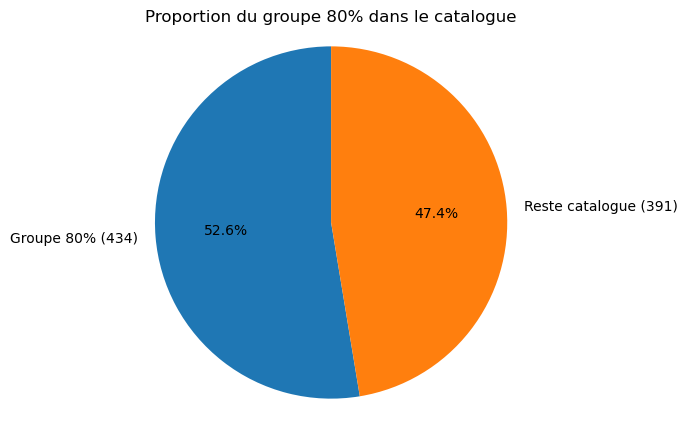

In [198]:
#____________camembert qui montre la proportion du groupe 80% (articles qui cumulent 80% des ventes en quantité)__________
#  les tranches du camembert
total_articles = len(df_merge)
reste_catalogue = total_articles - nb_articles_80

labels = [
    f"Groupe 80% ({nb_articles_80})",
    f"Reste catalogue ({reste_catalogue})"
]
valeurs = [nb_articles_80, reste_catalogue]

# Affichage du texte récapitulatif
part_groupe = (nb_articles_80 / total_articles * 100) if total_articles else 0.0
display(Markdown(f"**Groupe 80% : {nb_articles_80} articles ({part_groupe:.1f}% du catalogue)**"))

#  Camembert
plt.figure(figsize=(5,5))
plt.pie(valeurs, labels=labels, autopct="%.1f%%", startangle=90)
plt.title("Proportion du groupe 80% dans le catalogue")
plt.axis("equal")  # cercle
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse des stocks</h3>
</div>

In [199]:
######################################
# Calculer le nombre de mois de stock #
######################################

#________________________________Import de numpy______________________________________________________ 
import numpy as np
#_________________________________Création de la colonne Rotation de stock__________________________________

#Nombre de mois couverts par les ventes (à partir de df_final.post_date)
dates = pd.to_datetime(df_final["post_date"], errors="coerce")
if dates.notna().any():
    debut = dates.min().to_period("M")
    fin   = dates.max().to_period("M")
    NB_MOIS = int((fin - debut).n) + 1
 
else:
    NB_MOIS = 12  # si aucune date


# 2) Ventes numériques dans df_merge
df_merge["total_sales_num"] = pd.to_numeric(df_merge.get("total_sales"), errors="coerce").fillna(0).clip(lower=0)

# Création de la colonne  : Rotation de stock (ventes/mois) rotation_mensuelle = total_sales_num ÷ NB_MOIS
df_merge["Rotation de stock"] = df_merge["total_sales_num"] / NB_MOIS #NB_MOIS ≈ 30.

# 4) Aperçu
display(df_merge.head())
#_____________________________________Remplacement des "inf" par 0_____________________________________
#Remplacer +inf et -inf par 0 dans "Rotation de stock"
df_merge["Rotation de stock"] = df_merge["Rotation de stock"].replace([np.inf, -np.inf], 0)
#Vérifier combien d’infinis il y avait
# compter les +inf / -inf (sur colonnes numériques)
nb_inf = int(np.isinf(df_merge.select_dtypes(include=[float, int])).to_numpy().sum())

display(Markdown(f"**Nb de valeurs infinies remplacées : {nb_inf}**"))
#___________Effectuer le tri dans l'ordre décroissant du nombre de mois de stock dans le dataset df_merge_________________________________
#Stock numérique
df_merge["stock_quantity"] = pd.to_numeric(df_merge.get("stock_quantity"), errors="coerce").fillna(0)

#  Nombre de mois de stock = stock / Rotation de stock
# on évite division par 0 remplace 0 par NaN, puis NaN --> 0
rot = df_merge["Rotation de stock"].replace(0, np.nan)
df_merge["Mois de stock"] = (df_merge["stock_quantity"] / rot).replace([np.inf, -np.inf], np.nan).fillna(0).round(1)

# Tri décroissant + reset index
df_merge = df_merge.sort_values("Mois de stock", ascending=False).reset_index(drop=True)

#  Aperçu
display(Markdown("**Top 10 — Nombre de mois de stock (décroissant)**"))
colonnes_vue = [c for c in ["product_id","stock_quantity","total_sales","Rotation de stock","Mois de stock"] if c in df_merge.columns]
display(df_merge[colonnes_vue].head(10))
#_________________________Graphique en barre du flop 20 des produits qui ont le plus de mois de stock____________________________________

# product_type dans df_merge 
# clé commune alignée en numérique
df_merge["product_id"] = pd.to_numeric(df_merge["product_id"], errors="coerce")
map_type = (
    df_final[["product_id", "product_type"]]
      .dropna(subset=["product_id"])
      .drop_duplicates("product_id", keep="last")
      .assign(product_id=lambda d: pd.to_numeric(d["product_id"], errors="coerce"))
      .set_index("product_id")["product_type"]
)

df_merge["product_type"] = df_merge["product_id"].map(map_type).fillna("NA")

# Flop 20 des produits avec le plus de "Mois de stock" ---
col_mois = "Mois de stock"

# valeurs numériques finies
val = pd.to_numeric(df_merge[col_mois], errors="coerce")
df_plot = df_merge.loc[np.isfinite(val)].copy()
df_plot[col_mois] = val.loc[df_plot.index].round(1)

# top 20 plus gros (flop)
df_plot = df_plot.sort_values(col_mois, ascending=False).head(20)

# libellé "product_id — product_type"
df_plot["libelle"] = df_plot["product_id"].astype("Int64").astype(str) + " — " + df_plot["product_type"].astype(str)

# graphique
fig = px.bar(
    df_plot,
    x=col_mois, y="libelle",
    orientation="h", text=col_mois,
    title="Flop 20 — Produits avec le plus de mois de stock",
    labels={col_mois: "Mois de stock", "libelle": "Article (id — type)"}
)
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(yaxis=dict(categoryorder="total ascending"),
                  height=650, margin=dict(l=200, r=30, t=60, b=40))
fig.show()

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct,part_qte_cum,part_qte_cum_pct,total_sales_num,Rotation de stock
0,4867,1,9.9,121,instock,4.86,9.9,121,en_ligne,16148,both,356.4,0.002481,0.2 %,36.0,0.006260,0.6 %,0.006260,0.6 %,36.0,1.200000
1,4203,1,9.9,74,instock,5.01,9.9,74,en_ligne,15415,both,267.3,0.001860,0.2 %,27.0,0.004695,0.5 %,0.010955,1.1 %,27.0,0.900000
2,4275,1,14.9,62,instock,7.78,14.9,62,en_ligne,14864,both,357.6,0.002489,0.2 %,24.0,0.004173,0.4 %,0.015128,1.5 %,24.0,0.800000
3,4726,1,12.7,0,outofstock,6.82,12.7,0,en_ligne,14950,both,279.4,0.001945,0.2 %,22.0,0.003825,0.4 %,0.018953,1.9 %,22.0,0.733333
4,4647,1,28.5,45,instock,14.14,28.5,45,en_ligne,16525,both,627.0,0.004364,0.4 %,22.0,0.003825,0.4 %,0.022779,2.3 %,22.0,0.733333


**Nb de valeurs infinies remplacées : 0**

**Top 10 — Nombre de mois de stock (décroissant)**

,product_id,stock_quantity,total_sales,Rotation de stock,Mois de stock
0,4142,125,4.0,0.133333,937.5
1,6126,138,5.0,0.166667,828.0
2,4356,81,3.0,0.100000,810.0
3,4348,125,5.0,0.166667,750.0
4,4148,71,3.0,0.100000,710.0
5,4357,115,5.0,0.166667,690.0
6,4144,91,4.0,0.133333,682.5
7,5025,136,6.0,0.200000,680.0
8,4350,145,7.0,0.233333,621.4
9,4150,123,6.0,0.200000,615.0


In [200]:
####################################
# Valorisation des stocks en euros #
####################################

#__________________________Création de la colonne Valorisation des stocks en euros_________________________________________________
# _ la colonne "price_2" 
col_prix = "price_2" 

# Passer prix et stock en numérique (NaN --> 0 ; stock négatif coupé à 0)
cout_achat = pd.to_numeric(df_merge["purchase_price"], errors="coerce").fillna(0)
# pas de stock négatif
stock = pd.to_numeric(df_merge.get("stock_quantity_2"), errors="coerce").fillna(0).clip(lower=0)

# Nouvelle colonne : valorisation du stock en €
df_merge["Valorisation_stock_euros"] = cout_achat * stock

# aperçu )
display(Markdown("**Aperçu avec `Valorisation_stock_euros`(coût d’achat × stock**"))
display(df_merge.head(5))
#_____________________________Calculer la somme de la colonne "Valorisation_stock_euros"___________________________

# Somme de la colonne
valo_totale = float(df_merge["Valorisation_stock_euros"].sum())

# Affichage 
display(Markdown(f"**Valorisation totale des stocks : {valo_totale:,.2f} €**"))

**Aperçu avec `Valorisation_stock_euros`(coût d’achat × stock**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct,part_qte_cum,part_qte_cum_pct,total_sales_num,Rotation de stock,Mois de stock,product_type,Valorisation_stock_euros
0,4142,1,53.0,125,instock,32.15,53.0,125,en_ligne,11641,both,212.0,0.001476,0.1 %,4.0,0.000696,0.1 %,0.952008,95.2 %,4.0,0.133333,937.5,Champagne,4018.75
1,6126,1,135.0,138,instock,80.33,135.0,138,en_ligne,14923,both,675.0,0.004698,0.5 %,5.0,0.000869,0.1 %,0.917580,91.8 %,5.0,0.166667,828.0,Champagne,11085.54
2,4356,1,51.6,81,instock,31.00,51.6,81,en_ligne,12585,both,154.8,0.001077,0.1 %,3.0,0.000522,0.1 %,0.975135,97.5 %,3.0,0.100000,810.0,Champagne,2511.00
3,4348,1,59.0,125,instock,34.76,59.0,125,en_ligne,12586,both,295.0,0.002053,0.2 %,5.0,0.000869,0.1 %,0.914102,91.4 %,5.0,0.166667,750.0,Champagne,4345.00
4,4148,1,37.5,71,instock,21.88,37.5,71,en_ligne,1364,both,112.5,0.000783,0.1 %,3.0,0.000522,0.1 %,0.972527,97.3 %,3.0,0.100000,710.0,Champagne,1553.48


**Valorisation totale des stocks : 298,627.66 €**

In [201]:
##############################################
# Valorisation du nombre de produits en stock #
##############################################

#_______________calculer la somme de la colonne stock quantity_________________________________
# Somme des quantités (convertit en numérique, NaN -> 0)
df_merge["stock_quantity_2"] = pd.to_numeric(df_merge["stock_quantity_2"], errors="coerce").fillna(0)
total_stock = int(df_merge["stock_quantity_2"].sum())

# Affichage
display(Markdown(f"**Total des unités (de produits) en stock : {total_stock:}**"))

**Total des unités (de produits) en stock : 17822**

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

In [202]:
############################
# Analyse du taux de marge #
############################

#____________________________Création de la colonne Prix HT________________________________________________________________
# tax_class est vide, Le taux exact n’est pas stocké dans le fichier des produits
# donc il vient des règles de taxe du site (pays, classes de taxes):
#Pour un site en France : la “classe standard” est souvent 20%
TAUX_TVA = 0.20

#  Prix TTC en numérique
df_merge["price_2"] = pd.to_numeric(df_merge["price_2"], errors="coerce")

# Prix_HT = Prix_TTC / (1 + TVA)
df_merge["prix_ht"] = df_merge["price_2"] / (1 + TAUX_TVA)

# 4) Aperçu
display(Markdown("**Aperçu (price_2 → prix_ht)**"))
display(df_merge[["product_id", "price_2","product_type", "prix_ht"]].head(10))
#_____________________________Création de la colonne Taux de marge________________________________________________________________
# Colonnes numériques
df_merge["prix_ht"]        = pd.to_numeric(df_merge["prix_ht"], errors="coerce")
df_merge["purchase_price"] = pd.to_numeric(df_merge["purchase_price"], errors="coerce")

# Taux de marge = (prix_ht - purchase_price) / prix_ht 
df_merge["taux_marge"] = np.where(
    df_merge["prix_ht"] > 0,
    (df_merge["prix_ht"] - df_merge["purchase_price"]) / df_merge["prix_ht"],
    np.nan
)
# Version pourcentage 
df_merge["taux_marge_pct"] = (
    pd.to_numeric(df_merge["taux_marge"], errors="coerce") * 100
).round(1).map(lambda x: f"{x:.1f} %")
# Aperçu
display(Markdown("**Aperçu taux de marge (%)**"))
display(df_merge[["product_id","product_type","purchase_price","price_2","prix_ht","taux_marge","taux_marge_pct"]].head(10))

#__________________Afficher le prix minimum de la colonne "taux_marge"___________________________________________
# --- Min du taux de marge (valeur + %) ---
vals_min = pd.to_numeric(df_merge["taux_marge"], errors="coerce")
min_taux = vals_min.min()
idx_min  = vals_min.idxmin()

display(Markdown(f"**Min `taux_marge`** : {min_taux:.3f}  |  **({min_taux*100:.1f} %)**"))

#  ligne correspondante
cols = ["product_id","product_type","purchase_price","price_2","prix_ht","taux_marge"]
display(df_merge.loc[[idx_min], [c for c in cols if c in df_merge.columns]])

#____________Afficher le prix maximum de la colonne "taux_marge"_______________________________________________
# Max du taux de marge (en valeur et en %)
vals_max = pd.to_numeric(df_merge["taux_marge"], errors="coerce")
max_taux = vals_max.max()
idx_max  = vals_max.idxmax()

display(Markdown(f"**Max `taux_marge`** : {max_taux:.3f}  |  **({max_taux*100:.1f} %)**"))

# ligne correspondante
cols = ["product_id","product_type","purchase_price","price_2","prix_ht","taux_marge"]
display(df_merge.loc[[idx_max], [c for c in cols if c in df_merge.columns]])



**Aperçu (price_2 → prix_ht)**

,product_id,price_2,product_type,prix_ht
0,4142,53.0,Champagne,44.166667
1,6126,135.0,Champagne,112.500000
2,4356,51.6,Champagne,43.000000
3,4348,59.0,Champagne,49.166667
4,4148,37.5,Champagne,31.250000
5,4357,39.0,Champagne,32.500000
6,4144,49.0,Champagne,40.833333
7,5025,112.0,Champagne,93.333333
8,4350,79.5,Champagne,66.250000
9,4150,59.0,Champagne,49.166667


**Aperçu taux de marge (%)**

,product_id,product_type,purchase_price,price_2,prix_ht,taux_marge,taux_marge_pct
0,4142,Champagne,32.15,53.0,44.166667,0.272075,27.2 %
1,6126,Champagne,80.33,135.0,112.500000,0.285956,28.6 %
2,4356,Champagne,31.00,51.6,43.000000,0.279070,27.9 %
3,4348,Champagne,34.76,59.0,49.166667,0.293017,29.3 %
4,4148,Champagne,21.88,37.5,31.250000,0.299840,30.0 %
5,4357,Champagne,22.30,39.0,32.500000,0.313846,31.4 %
6,4144,Champagne,27.73,49.0,40.833333,0.320898,32.1 %
7,5025,Champagne,68.60,112.0,93.333333,0.265000,26.5 %
8,4350,Champagne,47.30,79.5,66.250000,0.286038,28.6 %
9,4150,Champagne,35.45,59.0,49.166667,0.278983,27.9 %


**Min `taux_marge`** : -6.350  |  **(-635.0 %)**

,product_id,product_type,purchase_price,price_2,prix_ht,taux_marge
684,4355,Champagne,77.48,12.65,10.541667,-6.349881


**Max `taux_marge`** : 0.478  |  **(47.8 %)**

,product_id,product_type,purchase_price,price_2,prix_ht,taux_marge
541,4401,Cognac,27.21,62.5,52.083333,0.477568


In [203]:
#____________________________Affichage de la ligne avec un taux de marge inférieur à 0_____________________________
# masque : True si taux_marge < 0
mask_marge_neg = pd.to_numeric(df_merge["taux_marge"], errors="coerce") < 0

# résumé + aperçu (toutes colonnes des lignes concernées)
display(Markdown(f"**Lignes avec taux de marge < 0 : {int(mask_marge_neg.sum())}**"))
display(df_merge.loc[mask_marge_neg])  

**Lignes avec taux de marge < 0 : 4**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct,part_qte_cum,part_qte_cum_pct,total_sales_num,Rotation de stock,Mois de stock,product_type,Valorisation_stock_euros,prix_ht,taux_marge,taux_marge_pct
667,7196,0,31.00,55,instock,31.20,31.00,55,hors_ligne,<NA>,both,0.0,0.0,0.0 %,0.0,0.0,0.0 %,1.0,100.0 %,0.0,0.0,0.0,Vin,1716.00,25.833333,-0.207742,-20.8 %
679,6324,0,92.00,18,instock,99.00,92.00,18,hors_ligne,<NA>,both,0.0,0.0,0.0 %,0.0,0.0,0.0 %,1.0,100.0 %,0.0,0.0,0.0,Vin,1782.00,76.666667,-0.291304,-29.1 %
684,4355,1,12.65,97,instock,77.48,12.65,97,en_ligne,12589,both,0.0,0.0,0.0 %,0.0,0.0,0.0 %,1.0,100.0 %,0.0,0.0,0.0,Champagne,7515.56,10.541667,-6.349881,-635.0 %
804,4864,0,8.30,0,outofstock,9.99,8.30,0,hors_ligne,15154,both,0.0,0.0,0.0 %,0.0,0.0,0.0 %,1.0,100.0 %,0.0,0.0,0.0,NA,0.00,6.916667,-0.444337,-44.4 %


In [204]:
#____________________________________Création d'un dataframe avec les taux positifs________________________________________
# S'assurer que le taux est numérique
tm = pd.to_numeric(df_merge["taux_marge"], errors="coerce")

#Garder uniquement les lignes à marge > 0
df_marge_pos = df_merge.loc[tm > 0].copy()

# colonne % 
df_marge_pos["taux_marge_pct"] = (tm.loc[df_marge_pos.index] * 100).round(1).map("{:.1f} %".format)

# Aperçu
display(Markdown(f"**Lignes avec taux de marge > 0 : {len(df_marge_pos)}**"))
display(df_marge_pos.head(10))

#____________________Afficher le prix minimum de la colonne "taux_marge"___________________________
# --- Min du taux de marge (valeur + %) ---
vals_min = pd.to_numeric(df_merge["taux_marge"], errors="coerce")
min_taux = vals_min.min()
idx_min  = vals_min.idxmin()

display(Markdown(f"**Min `taux_marge`** : {min_taux:.3f}  |  **({min_taux*100:.1f} %)**"))

#  ligne correspondante
cols = ["product_id","product_type","purchase_price","price_2","prix_ht","taux_marge"]
display(df_merge.loc[[idx_min], [c for c in cols if c in df_merge.columns]])

#_________________________Afficher le prix maximum de la colonne "taux_marge"_______________


**Lignes avec taux de marge > 0 : 818**

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,price_2,stock_quantity_2,etiquette_onsale,id_web,_merge,ca_par_article,part_ca,part_ca_pct,total_sales,part_qte,part_qte_pct,part_qte_cum,part_qte_cum_pct,total_sales_num,Rotation de stock,Mois de stock,product_type,Valorisation_stock_euros,prix_ht,taux_marge,taux_marge_pct
0,4142,1,53.0,125,instock,32.15,53.0,125,en_ligne,11641,both,212.0,0.001476,0.1 %,4.0,0.000696,0.1 %,0.952008,95.2 %,4.0,0.133333,937.5,Champagne,4018.75,44.166667,0.272075,27.2 %
1,6126,1,135.0,138,instock,80.33,135.0,138,en_ligne,14923,both,675.0,0.004698,0.5 %,5.0,0.000869,0.1 %,0.917580,91.8 %,5.0,0.166667,828.0,Champagne,11085.54,112.500000,0.285956,28.6 %
2,4356,1,51.6,81,instock,31.00,51.6,81,en_ligne,12585,both,154.8,0.001077,0.1 %,3.0,0.000522,0.1 %,0.975135,97.5 %,3.0,0.100000,810.0,Champagne,2511.00,43.000000,0.279070,27.9 %
3,4348,1,59.0,125,instock,34.76,59.0,125,en_ligne,12586,both,295.0,0.002053,0.2 %,5.0,0.000869,0.1 %,0.914102,91.4 %,5.0,0.166667,750.0,Champagne,4345.00,49.166667,0.293017,29.3 %
4,4148,1,37.5,71,instock,21.88,37.5,71,en_ligne,1364,both,112.5,0.000783,0.1 %,3.0,0.000522,0.1 %,0.972527,97.3 %,3.0,0.100000,710.0,Champagne,1553.48,31.250000,0.299840,30.0 %
5,4357,1,39.0,115,instock,22.30,39.0,115,en_ligne,9562,both,195.0,0.001357,0.1 %,5.0,0.000869,0.1 %,0.918449,91.8 %,5.0,0.166667,690.0,Champagne,2564.50,32.500000,0.313846,31.4 %
6,4144,1,49.0,91,instock,27.73,49.0,91,en_ligne,1662,both,196.0,0.001364,0.1 %,4.0,0.000696,0.1 %,0.950617,95.1 %,4.0,0.133333,682.5,Champagne,2523.43,40.833333,0.320898,32.1 %
7,5025,1,112.0,136,instock,68.60,112.0,136,en_ligne,13914,both,672.0,0.004677,0.5 %,6.0,0.001043,0.1 %,0.875152,87.5 %,6.0,0.200000,680.0,Champagne,9329.60,93.333333,0.265000,26.5 %
8,4350,1,79.5,145,instock,47.30,79.5,145,en_ligne,12588,both,556.5,0.003873,0.4 %,7.0,0.001217,0.1 %,0.774300,77.4 %,7.0,0.233333,621.4,Champagne,6858.50,66.250000,0.286038,28.6 %
9,4150,1,59.0,123,instock,35.45,59.0,123,en_ligne,1366,both,354.0,0.002464,0.2 %,6.0,0.001043,0.1 %,0.872022,87.2 %,6.0,0.200000,615.0,Champagne,4360.35,49.166667,0.278983,27.9 %


**Min `taux_marge`** : -6.350  |  **(-635.0 %)**

,product_id,product_type,purchase_price,price_2,prix_ht,taux_marge
684,4355,Champagne,77.48,12.65,10.541667,-6.349881


**Taux de marge moyen par type de produit**

,product_type,taux_marge,taux_marge_pct
1,Cognac,0.450676,45.1 %
6,Whisky,0.449189,44.9 %
2,Gin,0.428000,42.8 %
5,Vin,0.378446,37.8 %
4,NA,0.344302,34.4 %
3,Huile d'olive,0.249982,25.0 %
0,Champagne,0.047929,4.8 %


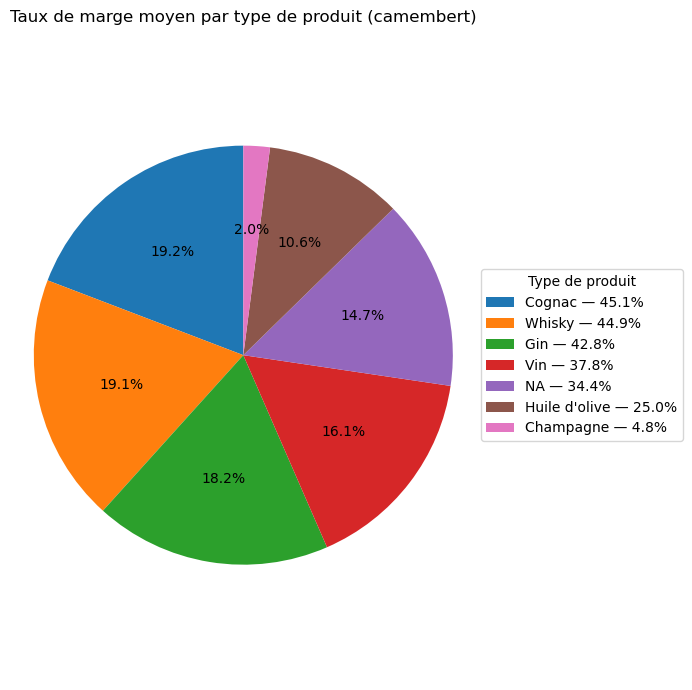

In [205]:
#_____________________Création d'un dataframe avec le taux de marge moyen par type de produit___________________________
# Taux numérique + type de produit
taux = pd.to_numeric(df_merge["taux_marge"], errors="coerce")
types = df_merge["product_type"].fillna("NA")

# Moyenne par type
marge_moy_type = (
    pd.DataFrame({"product_type": types, "taux_marge": taux})
      .dropna(subset=["taux_marge"])
      .groupby("product_type", as_index=False)["taux_marge"].mean()
      .sort_values("taux_marge", ascending=False)
)

# en pourcentage 
marge_moy_type["taux_marge_pct"] = (marge_moy_type["taux_marge"] * 100).round(1).map("{:.1f} %".format)
# Aperçu
display(Markdown("**Taux de marge moyen par type de produit**"))
display(marge_moy_type.head(10))
#___________________Affichage dans un graphique du taux de marge par type de produit__________________________________
# Données pour le graphe (en % numériques)
labels = marge_moy_type["product_type"].astype(str).tolist()
sizes  = (marge_moy_type["taux_marge"] * 100).tolist()  # en pourcentage

# Camembert + légende
fig, ax = plt.subplots(figsize=(7,7))
wedges, texts, autotexts = ax.pie(
    sizes,
    labels=None,                
    autopct=lambda p: f"{p:.1f}%", 
    startangle=90
)
ax.set_title("Taux de marge moyen par type de produit (camembert)")
ax.axis("equal")  

# Légende à droite, avec la couleur et le type (et le %)
legend_labels = [f"{lab} — {val:.1f}%" for lab, val in zip(labels, sizes)]
ax.legend(
    wedges, legend_labels,
    title="Type de produit",
    loc="center left", bbox_to_anchor=(1, 0.5) 
)

plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables stock, sales et price</h3>
</div>

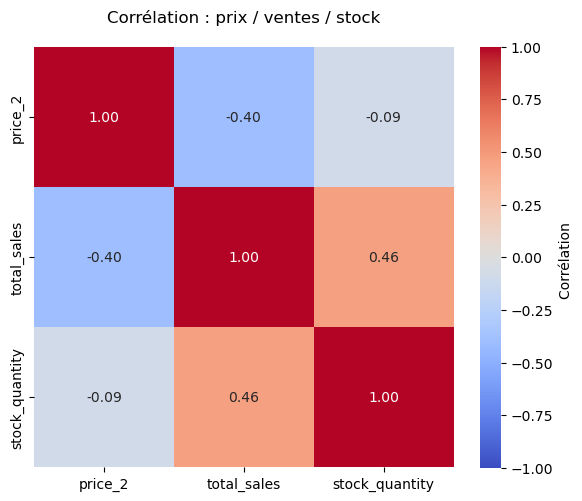

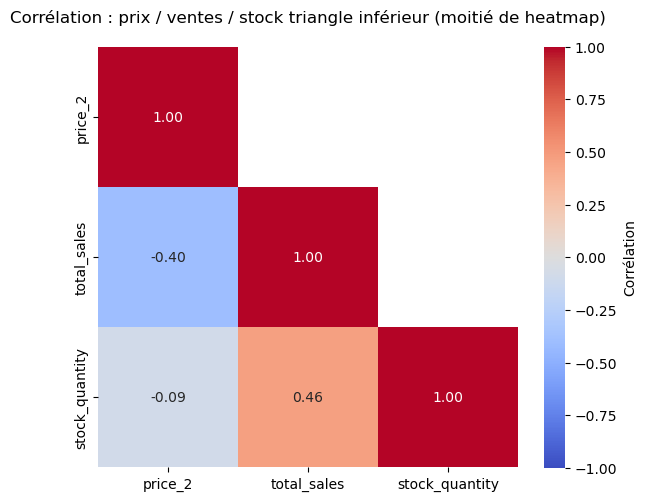

In [206]:
############################
# Analyse des corrélations #
############################

#__________________________Importation de Seaborn_________________________________________________________
import seaborn as sns
#__________________Création d'une heatmap de corrélation avec les variables stock, sales et price____________________
# Colonnes à prendre ( gère price_2 et total_sales_num)
cols = ["price_2", "total_sales", "stock_quantity"]
tmp = df_merge.copy()
for c in cols:
    tmp[c] = pd.to_numeric(tmp[c], errors="coerce")

# Matrice de corrélation
corr = tmp[cols].corr(method="pearson")

# eatmap 
plt.figure(figsize=(6, 5))
ax = sns.heatmap(
    corr, annot=True, fmt=".2f", square=True,
    vmin=-1, vmax=1, cmap="coolwarm",
    cbar_kws={"label": "Corrélation "}
)
ax.set_title("Corrélation : prix / ventes / stock", pad=18)  # pad = espace titre
plt.tight_layout()
plt.show()
#__________________On peut également créer un mask pour n'afficher qu'une demi heatmap____________________________________
# Colonnes à corréler
cols = ["price_2", "total_sales", "stock_quantity"]

# Matrice de corrélation
tmp = df_merge[cols].apply(pd.to_numeric, errors="coerce")
corr = tmp.corr(method="pearson")

# --- Mask pour n'afficher que la moitié ( triangle inférieur seulement) 
# masque le triangle supérieur 
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  
# pour n’afficher que le triangle supérieur :
#mask = np.tril(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(6,5))
ax = sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", square=True,
    vmin=-1, vmax=1, cmap="coolwarm",
    cbar_kws={"label": "Corrélation"}
)
ax.set_title("Corrélation : prix / ventes / stock triangle inférieur (moitié de heatmap)", pad=18)
plt.tight_layout()
plt.show()

In [207]:
#Que peut-on conclure des corrélations ?
#Prix--> Ventes (−0,40) : quand le prix monte, les ventes baissent en moyenne. Relation négative .

#Ventes--> Stock  (+0,46) : plus on vend, plus on a de stock Relation positive moyenne.

#Prix --> Stock (−0,09) : quasi aucun lien entre prix et stock. Les variations de prix n’expliquent pas le niveau de stock.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

In [208]:
#_______________________________Mettre le dataset df_merge sur un fichier Excel______________________________
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
fname = "df_merge_export.xlsx"
df_merge.to_excel(fname, sheet_name="df_merge", index=False)

print(f"Fichier créé :" , fname)

Fichier créé : df_merge_export.xlsx


In [209]:
#fichier CSV 
df_merge.to_csv("df_merge_export.csv", index=False, encoding="utf-8-sig")
